# W2 | From exploratory analysis to credible validation
## Respiratory emergency visits in Chile's DEIS emergency network, 2020-2024

**Group 02:** Benjamín Pinto and Sebastián Herrera · Business Intelligence IIB423T-1, Universidad del Desarrollo · W2 due 29 October 2026.

This notebook continues the W1/C1 project. It reads the **same uncleaned C1 reduced input**, copied unchanged to `data/input/emergency_id1_id2_all_dates_2020_2024.csv.gz`, checks that its SHA-256 fingerprint matches the C1 file, and does not modify any W1/C1 artifact. Run all cells from top to bottom. Every random operation uses `SEED = 2026`.

**Labels used throughout.** **Observation** = a result computed in this notebook. **Assumption** = something we cannot verify from these files. **Recommendation** = a managerial suggestion that follows from the evidence. **Revised** = a W1/C1 statement that W2 changes.

| Brief section | Notebook section |
|---|---|
| 1. Continue and correct W1/C1 | §1 |
| 3. Data-validation checks (run first, because the EDA depends on the cleaned data) | §2 |
| 2. Repaired and extended EDA | §3 |
| 4. Sampling and representativeness | §4 |
| 5. Leakage audit | §5 |
| 6. Train/validation/test datasets | §6 |
| Management summary, AI-use disclosure | §7, §8 |

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import sys

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from IPython.display import HTML, display

SEED = 2026
HERE = Path.cwd()
W2 = HERE.parent if HERE.name == 'notebooks' else HERE
assert (W2 / 'notebooks/W2_project.ipynb').exists(), 'Run from the GROUP_02_W2 folder or its notebooks/ folder'
INPUT = W2 / 'data/input/emergency_id1_id2_all_dates_2020_2024.csv.gz'
DICTIONARY = W2 / 'data/reference/Diccionario_AtencionesUrgencia.xlsx'
EXPECTED_SHA256 = '8132dc6b70fc09f8b6e1f7cb127e4be5dd82592be8734c4ebb916261684af390'
FIG, OUT, SPLITS = W2 / 'figures', W2 / 'data/processed', W2 / 'data/splits'
for folder in (FIG, OUT, SPLITS):
    folder.mkdir(parents=True, exist_ok=True)

sha = hashlib.sha256(INPUT.read_bytes()).hexdigest()
assert sha == EXPECTED_SHA256, f'Input differs from the C1 file: {sha}'

# Chart conventions: one y-axis per panel, thin lines, recessive grid, fixed colour order.
INK, MUTED, GRID = '#0b0b0b', '#52514e', '#d9d8d4'
SLOT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 170, 'font.size': 9.5,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.edgecolor': MUTED, 'axes.labelcolor': INK, 'text.color': INK,
                     'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.titleweight': 'bold',
                     'axes.titlesize': 10.5, 'lines.linewidth': 1.6, 'legend.frameon': False})

def tidy(ax, axis='y'):
    ax.grid(axis=axis, color=GRID, lw=.6)
    ax.set_axisbelow(True)

print('Python', sys.version.split()[0], '| pandas', pd.__version__, '| NumPy', np.__version__,
      '| matplotlib', matplotlib.__version__, '| scikit-learn', sklearn.__version__)
print('Input verified:', INPUT.relative_to(W2), '| SHA-256', sha[:16], '...')

Python 3.13.16 | pandas 3.0.1 | NumPy 2.4.3 | matplotlib 3.10.8 | scikit-learn 1.8.0
Input verified: data/input/emergency_id1_id2_all_dates_2020_2024.csv.gz | SHA-256 8132dc6b70fc09f8 ...


## 1. Continuity with W1 and C1, and feedback-to-action

### 1.1 Problem, KPI, unit of observation and decision (unchanged)

| Element | Definition carried from W1/C1 |
|---|---|
| Business problem | Respiratory illness creates seasonal surges in emergency demand across public care settings; Winter Campaign planners need to know *when* demand composition shifts. |
| Proposed user and decision | Public-network winter planning staff decide **when to intensify review of weekly demand by care setting** before and during the Winter Campaign. Shift, bed or staffing changes need capacity and clinical data that this project does not have. |
| KPI | **Weekly respiratory share (%)** = 100 × respiratory visits (`IdCausa = 2`) / all emergency visits (`IdCausa = 1`), same week and same reporting facilities. Supporting measure: weekly respiratory visit count. |
| Source unit of observation | One row = **aggregate count for one facility × date × cause**. It is not a patient and not a unique person. |
| Analytical units in W2 | Facility-date pairs (validation, sampling), facility-week (holdout design) and national Sunday-Saturday week (KPI). |
| Scope | DEIS *Atenciones de Urgencia* archives 2020-2024, cause IDs 1 and 2, 673 reporting facility IDs. |

### 1.2 Feedback-to-action table

The project incorporates **all four official evaluation comments received from the instructor on Certamen 1 (C1)**, alongside peer review and self-audit corrections. Each entry links directly to executable code and artifacts in this notebook.

| # | Source | Feedback / Issue | Correction in W2 | Notebook evidence |
|---|---|---|---|---|
| 1 | C1 Instructor Feedback | *"Presentación infiere efectos de cierres/reapertura sin identificarlos"* (Presentation infers school closure/reopening effects without identifying or controlling for them). | **Replaced all causal policy claims with descriptive observations.** The DEIS archives contain no stringency indices, school calendar dates, or mobility data. Mentions of closures/reopenings or viral competition (RSV vs influenza) are explicitly reclassified as external observational hypotheses for future linkage, not identified causal effects. | §1.3, §3.3, §3.4, Table 3.6 (items 5, 6) |
| 2 | C1 Instructor Feedback | *"Correlación primaria/hospitalaria puede responder a estacionalidad"* (Primary care vs. hospital correlation may be driven by shared seasonal cycles). | **Recomputed correlation on week-to-week log changes (first differences $\Delta \ln X_t$).** Level correlation ($r = 0.983$) was inflated by common smooth annual seasonality (both series peak every winter). Weekly changes filter out the shared trend; co-movement remains high ($r = 0.931$, $\rho = 0.884$), confirming high-frequency synchrony, but we clarify this reflects external epidemic shocks (shared community viral exposure), not proven operational patient diversion. | §3.3, Figure 2, Table 3.6 (item 4), `coupling_levels_vs_changes.csv` |
| 3 | C1 Instructor Feedback | *"Pearson no requiere normalidad bivariada descriptiva"* (Pearson's r does not require bivariate normality when used descriptively). | **Corrected theoretical statement on correlation.** In C1, we incorrectly stated that Pearson correlation assumes bivariate normality in descriptive analysis. We clarify that as a sample descriptive statistic measuring standardized linear co-variation, Pearson's $r$ requires **no distributional assumptions**. Bivariate normality is only required for inferential hypothesis tests ($p$-values, confidence intervals via Fisher's $z$) or when asserting that zero correlation equates to independence. We contrast descriptive linear co-variation (Pearson $r$) with descriptive monotonic rank co-variation (Spearman $\rho$). | §3.3 statistical note, Table 3.6 (item 9) |
| 4 | C1 Instructor Feedback | *"Estabilidad de panel no demuestra causa epidemiológica"* (Stability of the balanced facility panel does not prove an epidemiological cause). | **Clarified what panel stability proves and what it does not.** The 581-facility balanced panel (10.7% in 2020 to 28.5% in 2024) proves that the post-pandemic surge is **not an artifact of facility entry/exit composition bias** (new clinics opening). However, it **does not demonstrate an epidemiological cause**, because administrative visit counts cannot rule out changes in clinical diagnostic coding thresholds, diagnostic testing access, or patient consultation behavior (such as fear of hospitals during 2020 lockdowns). | §3.5, §3.6, Table 3.6 (item 10) |
| 5 | W1 Peer Review | Packaged reduced input covered only three peak weeks, so five-year results could not be rebuilt independently. | Reused the full-date C1 extract covering all 2020-2024 dates and added an automated **SHA-256 integrity verification** before any data processing. | Setup cell, §2 row-count log |
| 6 | Self-Audit (Data Validation) | C1 checked only keys, positive counts, and sums, but missed formatting quirks, facility-type transitions, reporting gaps, spikes, and official register join coverage. | Implemented **11 programmatic validation checks (V1-V11)** with explicit actions and row logs. Non-reported days are kept as *missing* (never zero-filled); 45 spike days are flagged and their KPI impact quantified. | §2, `validation_checks.csv`, `row_count_log.csv` |
| 7 | Self-Audit (Data Leakage) | C1's 581 common facilities panel and W1's 30% alert threshold were defined with 5-year hindsight, constituting future-information leakage for planning/forecasting. | Documented in the 8-risk leakage audit (L2, L6). The alert threshold is now learned exclusively on training weeks and evaluated on validation. | §5 (L2, L6), §6.5, `leakage_audit.csv` |
| 8 | Self-Audit (Boundary Weeks) | C1's age-band correlation matrix included two partial calendar boundary weeks (4 and 3 days), distorting weekly rate comparisons. | All weekly analyses in W2 strictly filter to the **260 complete 7-day weeks**. | §3.1, §3.3 |

### 1.3 What changes in the original conclusions

The status of each W1/C1 conclusion is filled in from the evidence in §2-§3 (see the table at the end of §3).

## 2. Data dictionary and programmatic validation

### 2.1 Concise data dictionary

Source definitions come from the official DEIS dictionary (`Diccionario_AtencionesUrgencia.xlsx`, sheets *DiccionarioSADU*, *Anexo 1*, *Anexo 2*). The dictionary describes the asset as aggregated (*Agrupados*), updated daily (*Diaria*), and sourced from emergency care records (DAU) in health centres and hospitals.

| Variable | Meaning | Expected type | Acceptable values | Missing-value meaning |
|---|---|---|---|---|
| `source_year` | Annual archive the row came from (added in C1 extraction) | int | 2020-2024; must equal year of `fecha` | Not allowed |
| `IdEstablecimiento` | Facility identifier (DEIS *Anexo 2*) | string | `NN-NNN` or six-digit code (e.g. `201069`); no surrounding spaces | Not allowed |
| `IdCausa` | Cause code: 1 = all emergency visits (*Sección 1. Total*), 2 = total respiratory causes | int | {1, 2} in this extract | Not allowed |
| `Total` | Emergency visits for the facility, date and cause | int | ≥ 0; equals sum of the five age bands; ID 2 ≤ ID 1 for the same facility-date | Not allowed. **0 = recorded zero**, not missing |
| `Menores_1`, `De_1_a_4`, `De_5_a_14`, `De_15_a_64`, `De_65_y_mas` | Visits by age band | int | ≥ 0 | Not allowed |
| `fecha` | Date of care (dd/mm/yyyy) | date | Within `source_year` | Not allowed |
| `semana` | DEIS statistical week label | int | 1-53 (labels collide at year boundaries; see V5) | Not allowed |
| `GLOSATIPOESTABLECIMIENTO` | Care-setting type on that date | category | Hospital, SAPU, SAR, SUR, CEAR | Not allowed |
| *absent facility-date row* | Facility did not report that day | — | — | **Missing (not reported)**: never imputed as zero in descriptive totals |
| `week_start` (derived) | Sunday that starts the Sunday-Saturday week of `fecha` | date | 2019-12-29 to 2024-12-29 | — |
| `complete_week` (derived) | National week contains 7 source dates | bool | 260 of 262 weeks are complete | — |
| `spike_flag` (derived) | Implausible facility-day (rule V9) | bool | Flagged, retained | — |

In [2]:
raw = pd.read_csv(INPUT, dtype={'IdEstablecimiento': 'string', 'fecha': 'string',
                                'GLOSATIPOESTABLECIMIENTO': 'string'})
KEY = ['source_year', 'IdEstablecimiento', 'fecha', 'IdCausa']
AGES = ['Menores_1', 'De_1_a_4', 'De_5_a_14', 'De_15_a_64', 'De_65_y_mas']
COUNTS = ['Total', *AGES]
TYPES = ['Hospital', 'SAPU', 'SAR', 'SUR', 'CEAR']

row_log, checks = [], []
def log_rows(step, frame, note):
    row_log.append({'step': step, 'rows': len(frame), 'note': note})

def record(check, rule, failing, action, before, after, detail=''):
    checks.append({'check': check, 'rule': rule, 'failing': failing, 'action': action,
                   'rows_before': before, 'rows_after': after, 'detail': detail})

log_rows('0 raw C1 reduced input', raw, 'cause IDs 1 and 2, all dates 2020-2024, uncleaned')
print(f'{len(raw):,} rows x {raw.shape[1]} columns')
display(raw.head(3))

2,169,824 rows x 12 columns


,source_year,IdEstablecimiento,IdCausa,Total,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas,fecha,semana,GLOSATIPOESTABLECIMIENTO
0,2020,26-704,1,14,0,0,1,13,0,16/06/2020,25,Hospital
1,2020,26-704,1,14,0,0,0,14,0,25/06/2020,26,Hospital
2,2020,26-704,1,14,0,1,2,10,1,26/06/2020,26,Hospital


In [3]:
# V1 - schema and types
expected = {'source_year': 'int64', 'IdEstablecimiento': 'string', 'IdCausa': 'int64', 'Total': 'int64',
            **{a: 'int64' for a in AGES}, 'fecha': 'string', 'semana': 'int64',
            'GLOSATIPOESTABLECIMIENTO': 'string'}
actual = raw.dtypes.astype(str).to_dict()
schema_bad = [c for c, t in expected.items() if c not in actual or actual[c] != t]
extra_cols = sorted(set(actual) - set(expected))
record('V1 schema and types', 'All 12 expected columns present with expected dtype; no extra columns',
       len(schema_bad) + len(extra_cols), 'Pass - no change', len(raw), len(raw),
       f'mismatched={schema_bad}, extra={extra_cols}')

# V2 - identifier presence and format
ids = raw.IdEstablecimiento
padded = ids.ne(ids.str.strip())
stripped = ids.str.strip()
bad_format = ~stripped.str.fullmatch(r'\d{2}-\d{3}|\d{6}')
merge_risk = (raw.assign(s=stripped).groupby('s').IdEstablecimiento.nunique().gt(1)).sum()
record('V2 facility identifier', 'ID present; matches NN-NNN or six digits; no surrounding spaces',
       int(ids.isna().sum() + padded.sum() + bad_format.sum()),
       'Corrected - whitespace stripped (no IDs merged)', len(raw), len(raw),
       f'null={int(ids.isna().sum())}, padded rows={int(padded.sum()):,}, '
       f'bad format after strip={int(bad_format.sum())}, IDs merged by strip={int(merge_risk)}')
raw['IdEstablecimiento'] = stripped
assert raw.IdEstablecimiento.nunique() == 673
log_rows('1 after V2 ID strip', raw, 'value correction only')

# V3 - duplicate source key
dup_mask = raw.duplicated(KEY, keep=False)
identical = all(len(g.drop_duplicates()) == 1 for _, g in raw.loc[dup_mask].groupby(KEY))
extra = int(raw.duplicated(KEY).sum())
clean = raw.drop_duplicates(KEY, keep='first').copy()
record('V3 duplicate key', 'Unique (source_year, facility, date, cause)', extra,
       'Corrected - identical extra copies removed', len(raw), len(clean),
       f'{int(dup_mask.sum())} rows share {int(dup_mask.sum()) - extra} keys; identical={identical}; '
       f'2023 all-visit total falls by {int(raw.loc[raw.duplicated(KEY) & raw.IdCausa.eq(1), "Total"].sum())}')
assert identical and extra == 2
log_rows('2 after V3 de-duplication', clean, 'two identical 2023 rows removed')
display(raw.loc[dup_mask])

,source_year,IdEstablecimiento,IdCausa,Total,Menores_1,De_1_a_4,De_5_a_14,De_15_a_64,De_65_y_mas,fecha,semana,GLOSATIPOESTABLECIMIENTO
1462024,2023,08-105,1,13,0,0,0,13,0,10/01/2023,2,Hospital
1462025,2023,08-105,1,13,0,0,0,13,0,10/01/2023,2,Hospital
1462091,2023,08-105,2,0,0,0,0,0,0,10/01/2023,2,Hospital
1462092,2023,08-105,2,0,0,0,0,0,0,10/01/2023,2,Hospital


In [4]:
# V4 - ranges and arithmetic
negative = int(clean[COUNTS].lt(0).any(axis=1).sum())
sum_gap = int(clean.Total.ne(clean[AGES].sum(axis=1)).sum())
record('V4 count ranges and age arithmetic', 'All counts >= 0 and Total = sum of five age bands',
       negative + sum_gap, 'Pass - no change', len(clean), len(clean),
       f'negative rows={negative}, age-sum mismatches={sum_gap}')

# V5 - date logic and week labels
clean['date'] = pd.to_datetime(clean.fecha, format='%d/%m/%Y', errors='coerce')
bad_date = int(clean.date.isna().sum())
wrong_year = int(clean.date.dt.year.ne(clean.source_year).sum())
bad_week = int((~clean.semana.between(1, 53)).sum())
clean['week_start'] = clean.date - pd.to_timedelta((clean.date.dt.day_of_week + 1) % 7, unit='D')
collisions = (clean.groupby(['source_year', 'semana']).week_start.nunique()
              .loc[lambda s: s.gt(1)].reset_index(name='distinct_sunday_weeks'))
record('V5 date logic', 'fecha parses; year = source_year; semana in 1-53; one label = one week',
       bad_date + wrong_year + bad_week + len(collisions),
       'Corrected - analysis weeks derived from dates (Sunday start); semana not used', len(clean), len(clean),
       f'unparsed={bad_date}, wrong year={wrong_year}, semana out of range={bad_week}, '
       f'labels spanning 2 weeks={len(collisions)}')

# V6 - category consistency
clean['type'] = clean.GLOSATIPOESTABLECIMIENTO.str.strip()
bad_type = int((~clean.type.isin(TYPES)).sum())
types_per_fac = clean.groupby('IdEstablecimiento').type.nunique()
types_per_fac_year = clean.groupby(['IdEstablecimiento', 'source_year']).type.nunique()
changers = types_per_fac[types_per_fac.gt(1)].index
type_history = (clean.loc[clean.IdEstablecimiento.isin(changers)]
                .groupby(['IdEstablecimiento', 'source_year']).type.first().unstack())
record('V6 care-setting category', 'Type in {Hospital, SAPU, SAR, SUR, CEAR}; stable within facility-year',
       bad_type + int(types_per_fac_year.gt(1).sum()),
       'Retained with justification - 19 facilities reclassified between years; type used as of each date',
       len(clean), len(clean),
       f'invalid labels={bad_type}, facility-years with 2+ types={int(types_per_fac_year.gt(1).sum())}, '
       f'facilities changing type across years={len(changers)}')
assert len(changers) == 19
display(type_history)

source_year,2020,2021,2022,2023,2024
IdEstablecimiento,,,,,
02-803,SAPU,SAR,SAR,SAR,SAR
04-903,SAPU,SAPU,SAPU,SAR,SAR
04-904,SAPU,SAR,SAR,SAR,SAR
05-826,SAPU,SAR,SAR,SAR,SAR
06-829,SAPU,SAR,SAR,SAR,SAR
07-808,SAPU,SAPU,SAPU,SAPU,SAR
13-911,SAPU,SAR,SAR,SAR,SAR
14-807,SAPU,SAR,SAR,SAR,SAR
15-800,SAPU,SAR,SAR,SAR,SAR


In [5]:
# V7 - cause pairing and logical order (one facility-date row with both causes)
fd = clean.pivot_table(index=['IdEstablecimiento', 'date', 'source_year', 'type', 'week_start'],
                       columns='IdCausa', values='Total', aggfunc='sum').reset_index()
fd.columns.name = None
fd = fd.rename(columns={1: 'all_visits', 2: 'resp_visits'})
resp_ages = clean.loc[clean.IdCausa.eq(2), ['IdEstablecimiento', 'date', *AGES]]
fd = fd.merge(resp_ages, on=['IdEstablecimiento', 'date'], how='left', validate='one_to_one')
unpaired = int(fd[['all_visits', 'resp_visits']].isna().any(axis=1).sum())
resp_gt_all = int(fd.resp_visits.gt(fd.all_visits).sum())
record('V7 cause pairing', 'Each facility-date has cause 1 and cause 2; respiratory <= all visits',
       unpaired + resp_gt_all, 'Pass - no change', len(clean), len(clean),
       f'facility-dates={len(fd):,}, missing pair={unpaired}, respiratory > all={resp_gt_all}')
assert len(fd) * 2 == len(clean)
log_rows('3 facility-date table (wide)', fd, 'one row per facility-date; both causes as columns')

# V8 - reporting completeness: absent facility-dates inside each facility-year reporting span
span = fd.groupby(['IdEstablecimiento', 'source_year']).date.agg(['min', 'max', 'nunique'])
span['gap_days'] = (span['max'] - span['min']).dt.days + 1 - span['nunique']
record('V8 reporting completeness', 'No absent facility-dates between a facility-year first and last report',
       int(span.gap_days.sum()),
       'Flagged as limitation - absent days kept missing (not zero); weekly reporting-days feature added',
       len(fd), len(fd),
       f'facility-years={len(span):,}, with gaps={int(span.gap_days.gt(0).sum())}, '
       f'absent facility-days inside spans={int(span.gap_days.sum()):,}')
print(f'V7 and V8 verified: {len(fd):,} paired facility-dates; 0 missing pairs; {int(span.gap_days.sum()):,} absent facility-days logged.')

V7 and V8 verified: 1,084,911 paired facility-dates; 0 missing pairs; 23,200 absent facility-days logged.


In [6]:
# V9 - implausible facility-day spikes (rule fixed before looking at its KPI impact)
nonzero_median = fd.loc[fd.all_visits.gt(0)].groupby('IdEstablecimiento').all_visits.median()
fd['fac_median_all'] = fd.IdEstablecimiento.map(nonzero_median)
spike_volume = fd.all_visits.gt(10 * fd.fac_median_all) & fd.all_visits.ge(100)
spike_share = fd.all_visits.ge(500) & fd.resp_visits.ge(0.95 * fd.all_visits)
fd['spike_flag'] = spike_volume | spike_share
record('V9 implausible spikes', 'all visits <= 10x facility median (when >= 100), and not >= 95% respiratory at >= 500 visits',
       int(fd.spike_flag.sum()), 'Flagged, retained - cannot verify against source; KPI sensitivity in section 3',
       len(fd), len(fd),
       f'volume rule={int(spike_volume.sum())}, share rule={int(spike_share.sum())}, '
       f'visits on flagged days={int(fd.loc[fd.spike_flag, "all_visits"].sum()):,}')
display(fd.loc[fd.spike_flag].nlargest(5, 'all_visits')[['IdEstablecimiento', 'date', 'type', 'all_visits',
                                                         'resp_visits', 'fac_median_all']])

# V10 - recorded zeros
zero_all = fd.all_visits.eq(0)
fac_never = fd.groupby('IdEstablecimiento').all_visits.sum().eq(0)
record('V10 recorded zeros', 'Zero rows are recorded values; check concentration and always-zero facilities',
       int(zero_all.sum()), 'Retained with justification - valid recorded zeros; always-zero IDs flagged',
       len(fd), len(fd),
       f'facility-days with 0 visits={int(zero_all.sum()):,} '
       f'({100 * fd.loc[zero_all, "type"].eq("SUR").mean():.1f}% SUR), '
       f'facilities never >0={int(fac_never.sum())}, days all>0 & resp=0={int((~zero_all & fd.resp_visits.eq(0)).sum()):,}')

,IdEstablecimiento,date,type,all_visits,resp_visits,fac_median_all
803727,20-102,2022-06-18,Hospital,5643,30,163.0
1052270,29-103,2022-12-14,Hospital,4370,4318,65.0
1052361,29-103,2023-03-17,Hospital,1437,241,65.0
1056062,29-107,2020-04-29,Hospital,1413,290,45.0
141572,05-927,2021-10-31,SAR,1340,159,46.0


In [7]:
# V11 - join coverage against the DEIS facility register in the dictionary (Anexo 2, dated 08-07-2022)
register = pd.read_excel(DICTIONARY, sheet_name='Anexo 2', header=None, skiprows=7).iloc[:, 2:5]
register.columns = ['IdEstablecimiento', 'register_type', 'official_name']
register = register.dropna(subset=['IdEstablecimiento'])
register['IdEstablecimiento'] = register.IdEstablecimiento.astype(str).str.strip()
assert register.IdEstablecimiento.is_unique
fd['in_register'] = fd.IdEstablecimiento.isin(register.IdEstablecimiento)
join_cov = fd.groupby('source_year').apply(lambda g: pd.Series({
    'facility_ids': g.IdEstablecimiento.nunique(),
    'id_coverage_pct': 100 * g.drop_duplicates('IdEstablecimiento').in_register.mean(),
    'visit_coverage_pct': 100 * g.loc[g.in_register, 'all_visits'].sum() / g.all_visits.sum()}),
    include_groups=False)
unmatched = sorted(set(fd.IdEstablecimiento) - set(register.IdEstablecimiento))
record('V11 register join coverage', 'Every facility ID found in the 2022 DEIS register (Anexo 2)',
       len(unmatched), 'Flagged - no join used in W2; would need a dated register before any geographic use',
       len(fd), len(fd), f'unmatched IDs={len(unmatched)} of {fd.IdEstablecimiento.nunique()}; '
       f'minimum yearly visit coverage={join_cov.visit_coverage_pct.min():.2f}%')
display(join_cov.round(2))

,facility_ids,id_coverage_pct,visit_coverage_pct
source_year,,,
2020,607.0,98.19,98.77
2021,635.0,98.74,99.09
2022,638.0,98.90,99.63
2023,642.0,98.29,99.71
2024,640.0,97.81,99.14


In [8]:
check_table = pd.DataFrame(checks)
check_table['result'] = np.where(check_table.failing.eq(0), 'PASS', 'FINDING - see action')
check_table.to_csv(OUT / 'validation_checks.csv', index=False)
pd.set_option('display.max_colwidth', 120)
display(check_table[['check', 'result', 'failing', 'action', 'rows_before', 'rows_after', 'detail']])

,check,result,failing,action,rows_before,rows_after,detail
0,V1 schema and types,PASS,0,Pass - no change,2169824,2169824,"mismatched=[], extra=[]"
1,V2 facility identifier,FINDING - see action,98322,Corrected - whitespace stripped (no IDs merged),2169824,2169824,"null=0, padded rows=98,322, bad format after strip=0, IDs merged by strip=0"
2,V3 duplicate key,FINDING - see action,2,Corrected - identical extra copies removed,2169824,2169822,4 rows share 2 keys; identical=True; 2023 all-visit total falls by 13
3,V4 count ranges and age arithmetic,PASS,0,Pass - no change,2169822,2169822,"negative rows=0, age-sum mismatches=0"
4,V5 date logic,FINDING - see action,3,Corrected - analysis weeks derived from dates (Sunday start); semana not used,2169822,2169822,"unparsed=0, wrong year=0, semana out of range=0, labels spanning 2 weeks=3"
5,V6 care-setting category,PASS,0,Retained with justification - 19 facilities reclassified between years; type used as of each date,2169822,2169822,"invalid labels=0, facility-years with 2+ types=0, facilities changing type across years=19"
6,V7 cause pairing,PASS,0,Pass - no change,2169822,2169822,"facility-dates=1,084,911, missing pair=0, respiratory > all=0"
7,V8 reporting completeness,FINDING - see action,23200,Flagged as limitation - absent days kept missing (not zero); weekly reporting-days feature added,1084911,1084911,"facility-years=3,162, with gaps=872, absent facility-days inside spans=23,200"
8,V9 implausible spikes,FINDING - see action,45,"Flagged, retained - cannot verify against source; KPI sensitivity in section 3",1084911,1084911,"volume rule=45, share rule=1, visits on flagged days=26,437"
9,V10 recorded zeros,FINDING - see action,35424,Retained with justification - valid recorded zeros; always-zero IDs flagged,1084911,1084911,"facility-days with 0 visits=35,424 (85.3% SUR), facilities never >0=9, days all>0 & resp=0=101,006"


### 2.2 Validation results and actions

**Observation.** Four checks pass unchanged (V1 schema, V4 ranges/arithmetic, V6 labels within each facility-year, V7 cause pairing). Seven produce findings, and none is handled silently:

* **Corrected (values or rows changed):** V2 stripped trailing spaces from 98,322 facility-ID cells. No IDs merged, so 673 distinct facilities remain and rows are unchanged. V3 removed 2 identical extra rows (2,169,824 → 2,169,822; 2023 all visits −13). V5 confirmed that DEIS `semana` labels map to two different weeks in 3 year-boundary cases, so every weekly result uses the date-derived Sunday week.
* **Retained with justification:** V6 found 19 facilities that change care-setting type *between* years (mostly SAPU → SAR upgrades). These are genuine reclassifications, so each row keeps the type recorded on its date. V10 found 35,424 zero-visit facility-days (85.3% at rural SUR posts) and 9 facility IDs that never record a visit. The DEIS dictionary defines these as recorded counts, so they stay as zeros.
* **Flagged as limitations:** V8 found 23,200 absent facility-days inside facility-year reporting spans (872 of 3,162 facility-years). An absent row means *not reported*, so it is never filled with zero. V9 flags 45 implausible facility-days, e.g. 5,643 visits at facility 20-102 on 18 Jun 2022 against a median of 163/day, and 4,370 visits with 99% respiratory at 29-103 on 14 Dec 2022. They are retained because we cannot verify them against the original DAU records; §3.1 shows their KPI impact. V11 found 27 of 673 IDs absent from the 2022 DEIS register. Matched IDs still cover ≥ 98.77% of visits every year, and no join is used.

**Row counts.** The only row reduction is V3 (−2 rows). The full log of every derived table is printed at the end of §6 and saved to `data/processed/row_count_log.csv`. The check table is saved to `data/processed/validation_checks.csv`.

## 3. Revised exploratory data analysis

### 3.1 Updated descriptive statistics and denominators

**Denominators.** The KPI is a *pooled ratio*: total respiratory visits divided by total emergency visits over the same facility-days. It is **not** the average of facility shares, because small facilities would then carry the same weight as large hospitals. Neither ratio uses population as a denominator, so neither is an incidence rate. **Exclusions:** the two partial national weeks (4 and 3 days) are excluded from weekly comparisons only. Spike days (V9) are retained and their impact is shown in the sensitivity column. Absent facility-days (V8) contribute nothing; they are not zero-filled.

In [9]:
weekly = (fd.groupby('week_start')
          .agg(all_visits=('all_visits', 'sum'), resp_visits=('resp_visits', 'sum'),
               source_days=('date', 'nunique'), reporting_facilities=('IdEstablecimiento', 'nunique'),
               spike_days=('spike_flag', 'sum'))
          .reset_index())
weekly['week_end'] = weekly.week_start + pd.Timedelta(days=6)
weekly['reporting_year'] = weekly.week_end.dt.year
weekly['complete_week'] = weekly.source_days.eq(7)
weekly['resp_share_pct'] = 100 * weekly.resp_visits / weekly.all_visits
assert len(weekly) == 262 and weekly.complete_week.sum() == 260
cw = weekly.loc[weekly.complete_week].copy()
log_rows('4 national weekly table', weekly, '262 Sunday-Saturday weeks')
log_rows('5 complete national weeks', cw, 'two partial boundary weeks excluded from weekly comparisons')

big = fd.groupby(['IdEstablecimiento', 'source_year'])[['all_visits', 'resp_visits']].sum()
fac_share = (100 * big.resp_visits / big.all_visits).where(big.all_visits.ge(1000))
no_spike = fd.loc[~fd.spike_flag].groupby('source_year')[['all_visits', 'resp_visits']].sum()
annual = fd.groupby('source_year').agg(
    reporting_facilities=('IdEstablecimiento', 'nunique'), facility_days=('date', 'size'),
    all_visits=('all_visits', 'sum'), resp_visits=('resp_visits', 'sum'))
annual['absent_facility_days'] = span.groupby('source_year').gap_days.sum()
annual['kpi_pooled_share_pct'] = 100 * annual.resp_visits / annual.all_visits
annual['mean_facility_share_pct'] = fac_share.groupby('source_year').mean()
annual['median_weekly_share_pct'] = cw.groupby('reporting_year').resp_share_pct.median()
annual['kpi_without_spike_days_pct'] = 100 * no_spike.resp_visits / no_spike.all_visits
annual['under15_pct_of_resp'] = 100 * fd.groupby('source_year')[['Menores_1', 'De_1_a_4', 'De_5_a_14']].sum().sum(axis=1) / annual.resp_visits
annual['primary_care_pct_of_resp'] = 100 * fd.loc[fd.type.isin(['SAPU', 'SAR', 'SUR'])].groupby('source_year').resp_visits.sum() / annual.resp_visits

c1_annual = pd.read_csv(W2 / 'data/reference/c1_annual_summary.csv').set_index('year')
assert (annual.all_visits.values == c1_annual.all_emergency_visits.values).all()
assert (annual.resp_visits.values == c1_annual.respiratory_visits.values).all()
annual.round(2).to_csv(OUT / 'annual_descriptives_w2.csv')
display(annual.round(2))
pooled_all = 100 * annual.resp_visits.sum() / annual.all_visits.sum()
print(f'Five-year pooled KPI: {pooled_all:.2f}% | facility-years with >=1,000 visits used for mean of shares: '
      f'{int(fac_share.notna().sum())} of {len(fac_share)}')
print('Max absolute change in annual KPI when spike days are excluded:',
      f"{(annual.kpi_pooled_share_pct - annual.kpi_without_spike_days_pct).abs().max():.3f} percentage points")

,reporting_facilities,facility_days,all_visits,resp_visits,absent_facility_days,kpi_pooled_share_pct,mean_facility_share_pct,median_weekly_share_pct,kpi_without_spike_days_pct,under15_pct_of_resp,primary_care_pct_of_resp
source_year,,,,,,,,,,,
2020,607,194541,11382496,1223447,5515,10.75,11.68,6.65,10.75,30.05,71.08
2021,635,220406,13851594,1381568,5074,9.97,10.06,9.58,9.97,41.09,69.89
2022,638,223158,19491232,4812171,3850,24.69,25.77,25.35,24.68,50.71,71.78
2023,642,222476,19194227,5557541,4473,28.95,30.93,29.89,28.96,46.34,75.27
2024,640,224330,19436048,5541628,4288,28.51,30.74,29.29,28.51,40.72,75.87


Five-year pooled KPI: 22.21% | facility-years with >=1,000 visits used for mean of shares: 2994 of 3162
Max absolute change in annual KPI when spike days are excluded: 0.008 percentage points


**Observation.** The annual totals reproduce C1 exactly (asserted against `annual_summary.csv`). Three new columns change how they should be read:

* **Pooled KPI vs. mean of facility shares.** In 2022-2024 the unweighted mean of facility shares (25.77%, 30.93%, 30.74%) is about 1-2 points *above* the pooled KPI (24.69%, 28.95%, 28.51%). Facilities with smaller totals therefore tend to have higher respiratory shares. The pooled ratio is the right KPI for network-level planning, but it hides this heterogeneity (Figure 1).
* **Annual vs. weekly view.** In 2020 the median complete week had a 6.65% share, while the annual pooled value is 10.75%. The annual figure is pulled up by the March 2020 surge. An annual average is a weak summary of a seasonal process.
* **Robustness of the KPI to data issues.** Excluding the 45 spike days changes any annual KPI by at most 0.008 percentage points. Absent facility-days (3,850-5,515 per year, about 2% of facility-days) reduce visit *counts* but do not bias the share unless non-reporting differs between respiratory and other visits. That cannot be tested with these files (**Assumption**).

### 3.2 Figure 1 - Distribution: weekly KPI and facility-level heterogeneity

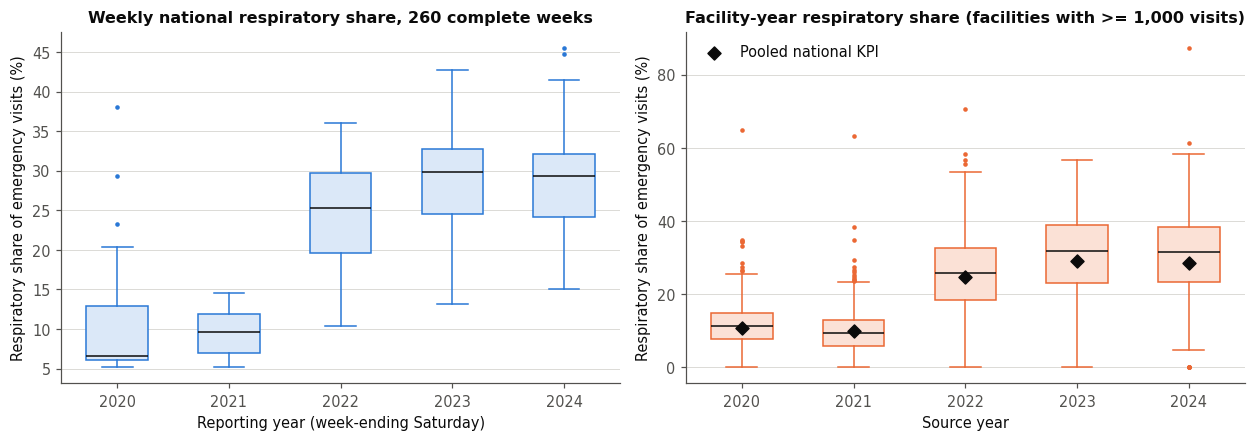

,count,10%,50%,90%
source_year,,,,
2020,559.0,5.1,11.2,18.2
2021,600.0,3.5,9.3,17.7
2022,609.0,13.4,25.6,38.6
2023,612.0,17.1,31.9,43.2
2024,614.0,16.5,31.4,43.2


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1))
years = list(range(2020, 2025))
data = [cw.loc[cw.reporting_year.eq(y), 'resp_share_pct'] for y in years]
axes[0].boxplot(data, tick_labels=[str(y) for y in years], widths=.55, patch_artist=True,
                boxprops={'facecolor': '#dbe8f8', 'edgecolor': SLOT[0]}, medianprops={'color': INK},
                whiskerprops={'color': SLOT[0]}, capprops={'color': SLOT[0]},
                flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': SLOT[0], 'markeredgecolor': 'none'})
axes[0].set(title='Weekly national respiratory share, 260 complete weeks',
            ylabel='Respiratory share of emergency visits (%)', xlabel='Reporting year (week-ending Saturday)')
tidy(axes[0])
fs = fac_share.dropna().reset_index(name='share')
data = [fs.loc[fs.source_year.eq(y), 'share'] for y in years]
axes[1].boxplot(data, tick_labels=[str(y) for y in years], widths=.55, patch_artist=True,
                boxprops={'facecolor': '#fbe1d6', 'edgecolor': SLOT[1]}, medianprops={'color': INK},
                whiskerprops={'color': SLOT[1]}, capprops={'color': SLOT[1]},
                flierprops={'marker': 'o', 'markersize': 3, 'markerfacecolor': SLOT[1], 'markeredgecolor': 'none'})
axes[1].scatter(range(1, 6), annual.kpi_pooled_share_pct, marker='D', s=36, color=INK, zorder=3,
                label='Pooled national KPI')
axes[1].set(title='Facility-year respiratory share (facilities with >= 1,000 visits)',
            ylabel='Respiratory share of emergency visits (%)', xlabel='Source year')
axes[1].legend(loc='upper left')
tidy(axes[1])
fig.tight_layout(); fig.savefig(FIG / 'fig1_distribution_weekly_and_facility_share.png', bbox_inches='tight'); plt.show()
spread = fs.groupby('source_year').share.describe(percentiles=[.1, .5, .9])[['count', '10%', '50%', '90%']]
display(spread.round(1))

**What Figure 1 shows.** Left: the weekly KPI is concentrated around 6-13% in 2020-2021, then shifts up and widens in 2022-2024 (2023 interquartile range 24.5-32.8%). Its upper tail reaches 45.56% in May 2024. Right: facilities differ widely within the same year. In 2023 the 10th-90th percentile of facility shares runs from 17.1% to 43.2%, around a pooled national value of 28.95%.

**What it does not show.** It shows nothing about *why* shares differ: catchment population, facility size, case mix and local coding practice are not in the data. A higher share is not higher disease risk, because the denominator is visits, not residents. Facility-years with fewer than 1,000 visits (168 of 3,162) are excluded from the right panel only, because their shares are unstable. They remain in every KPI.

### 3.3 Figure 2 - Relationship: is the C1 "coupling" more than shared seasonality?

C1 correlated weekly *levels*. When two series both rise every winter, a high level correlation can come from the common seasonal trend alone. A stricter check correlates **week-to-week log changes**: do the two series move up and down *in the same week*, beyond their shared trend?

,pair,weeks,pearson_levels,spearman_levels,pearson_weekly_log_change,spearman_weekly_log_change
0,hospital vs primary_care,260,0.983,0.984,0.931,0.884
1,under_1 vs age_65_plus,260,0.775,0.834,0.543,0.516
2,resp_visits vs all_visits,260,0.881,0.932,0.777,0.787


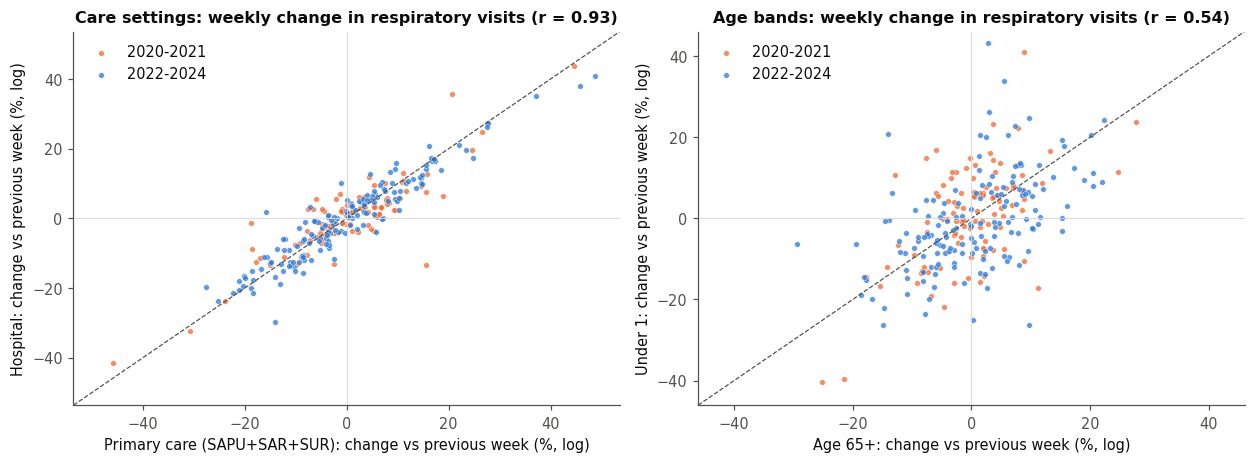

In [11]:
resp_rows = clean.loc[clean.IdCausa.eq(2)]
complete_weeks = set(cw.week_start)
by_setting = resp_rows.groupby(['week_start', 'type']).Total.sum().unstack(fill_value=0)
by_setting = by_setting.loc[by_setting.index.isin(complete_weeks)]
pair_setting = pd.DataFrame({'hospital': by_setting['Hospital'],
                             'primary_care': by_setting[['SAPU', 'SAR', 'SUR']].sum(axis=1)})
by_age = resp_rows.groupby('week_start')[AGES].sum()
by_age = by_age.loc[by_age.index.isin(complete_weeks)]
pair_age = pd.DataFrame({'under_1': by_age['Menores_1'], 'age_65_plus': by_age['De_65_y_mas']})

def coupling(frame):
    a, b = frame.columns
    ch = np.log(frame).diff().dropna()
    return {'pair': f'{a} vs {b}', 'weeks': len(frame),
            'pearson_levels': frame[a].corr(frame[b]),
            'spearman_levels': frame[a].corr(frame[b], method='spearman'),
            'pearson_weekly_log_change': ch[a].corr(ch[b]),
            'spearman_weekly_log_change': ch[a].corr(ch[b], method='spearman')}

coupling_table = pd.DataFrame([coupling(pair_setting), coupling(pair_age),
                               coupling(cw.set_index('week_start')[['resp_visits', 'all_visits']])])
coupling_table.round(3).to_csv(OUT / 'coupling_levels_vs_changes.csv', index=False)
display(coupling_table.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3))
for ax, frame, labels, title in [
        (axes[0], pair_setting, ('Primary care (SAPU+SAR+SUR)', 'Hospital'), 'Care settings'),
        (axes[1], pair_age, ('Age 65+', 'Under 1'), 'Age bands')]:
    ch = 100 * np.log(frame).diff().dropna()
    x, y = (ch.iloc[:, 1], ch.iloc[:, 0])
    post = ch.index.year >= 2022
    ax.scatter(x[~post], y[~post], s=14, color=SLOT[1], alpha=.75, label='2020-2021', edgecolor='white', lw=.4)
    ax.scatter(x[post], y[post], s=14, color=SLOT[0], alpha=.75, label='2022-2024', edgecolor='white', lw=.4)
    lim = np.nanpercentile(np.abs(np.r_[x, y]), 99.5)
    ax.plot([-lim, lim], [-lim, lim], color=MUTED, lw=.8, ls='--')
    ax.axhline(0, color=GRID, lw=.6); ax.axvline(0, color=GRID, lw=.6)
    r = x.corr(y)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim),
           title=f'{title}: weekly change in respiratory visits (r = {r:.2f})',
           xlabel=f'{labels[0]}: change vs previous week (%, log)',
           ylabel=f'{labels[1]}: change vs previous week (%, log)')
    ax.legend(loc='upper left')
fig.tight_layout(); fig.savefig(FIG / 'fig2_relationship_weekly_changes.png', bbox_inches='tight'); plt.show()

**Observation (revised C1 claim).** After removing the shared seasonal trend:
* **Hospital vs. primary care** weekly changes still correlate strongly (Pearson 0.931, Spearman 0.884; levels 0.983). The C1 finding that both settings rise and fall *in the same weeks* survives the stricter test.
* **Under-1 vs. 65+** drops from 0.775 (levels) to 0.543 (changes). C1's statement that the "seasonal severity hierarchy is strongly monotonic" across age bands mostly reflected the shared annual cycle, so it is **withdrawn**.

**Statistical note on correlation and distributional assumptions (Instructor Correction):** In C1, we mistakenly stated that Pearson correlation requires bivariate normality as a descriptive measure. As a sample descriptive statistic measuring standardized linear co-variation ($r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{(n-1) s_x s_y}$), Pearson's $r$ is non-parametric—it requires **no distributional assumptions whatsoever**. Bivariate normality is only required for **inferential hypothesis testing** (such as computing $p$-values via Student's $t$ or confidence intervals using Fisher's $z$-transformation) or for asserting that $r = 0$ implies statistical independence. In contrast, Spearman's rank correlation ($\rho$) evaluates monotonic association and is invariant to monotonic non-linear transformations. Here, Pearson and Spearman yield very close results ($r = 0.931$ vs $\rho = 0.884$ on weekly log changes), demonstrating robust synchronous linear and monotonic co-variation across settings.

**Association, not causation (Instructor Correction on Seasonality and Policy):** Co-movement does not show that one setting *drives* the other, that patients are transferred between them, or that they share an operational mechanism ("operational coupling" in C1). As the instructor pointed out, level correlations were heavily inflated by shared winter seasonality. Even after differencing, synchronous weekly shocks reflect common external community exposure (circulating respiratory pathogens and weather), not internal operational transmission. Furthermore, these administrative files contain no virological, school calendar, or policy indicators; references to specific virus timing (RSV vs. influenza) or school closure impacts are **unverified external hypotheses**, not empirical findings.

**Managerial reading.** Because the two settings move together week to week, **a surge signal in one setting is an early-warning cue for the other**. Planners should still not treat hospital and primary-care capacity as substitutes on the basis of this evidence.

### 3.4 Figure 3 - Over time and by segment: seasonal timing of the KPI and care-setting mix

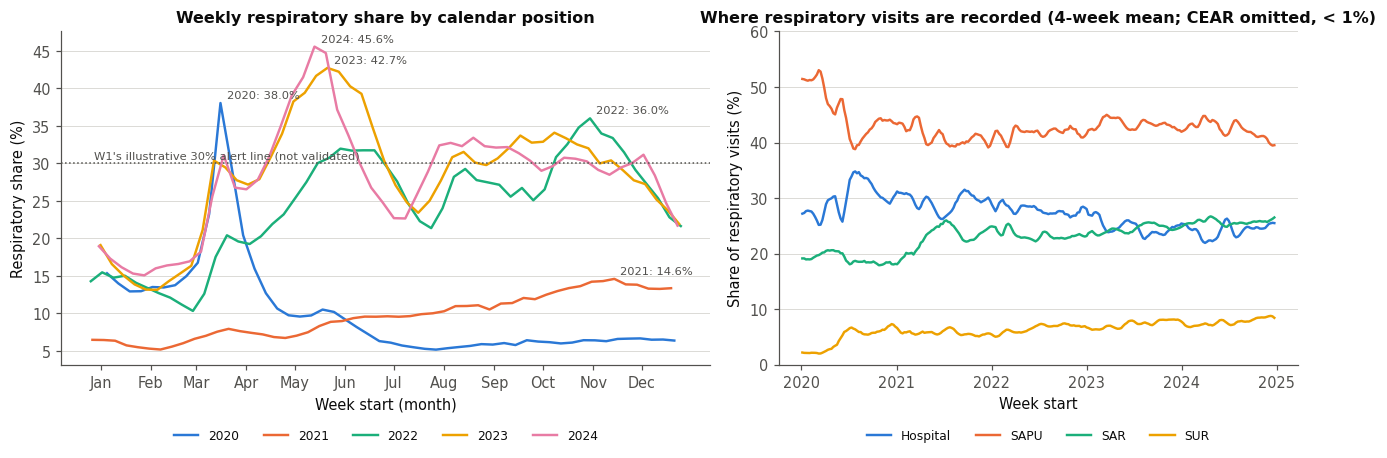

,peak_volume_week,resp_visits,resp_share_pct,peak_share_week,first_week_share_ge_30pct,weeks_share_ge_30pct
reporting_year,,,,,,
2020,2020-03-15,103314,38.04,2020-03-15,2020-03-15,1
2021,2021-11-14,47697,14.61,2021-11-14,NaT,0
2022,2022-10-30,161522,36.00,2022-10-30,2022-05-15,13
2023,2023-05-14,189297,41.66,2023-05-21,2023-03-12,25
2024,2024-05-12,203353,45.56,2024-05-12,2024-03-17,23


all facilities                               \
type                  CEAR Hospital   SAPU    SAR   SUR   
source_year                                               
2020                  0.46    28.46  48.09  19.36  3.63   
2024                  0.00    24.13  42.28  25.76  7.82   

            excluding 19 reclassified                               
type                             CEAR Hospital   SAPU    SAR   SUR  
source_year                                                         
2020                             0.48    29.48  46.43  20.05  3.56  
2024                             0.00    25.33  43.82  22.64  8.21

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3), gridspec_kw={'width_ratios': [1.25, 1]})
for i, y in enumerate(years):
    s = cw.loc[cw.reporting_year.eq(y)].sort_values('week_start')
    # days from 1 January of the reporting year (a week starting in late December is negative)
    x = (s.week_start - pd.Timestamp(year=y, month=1, day=1)).dt.days
    axes[0].plot(x, s.resp_share_pct, color=SLOT[i], label=str(y))
    k = s.resp_share_pct.idxmax()
    axes[0].annotate(f"{y}: {s.resp_share_pct[k]:.1f}%", (x[k], s.resp_share_pct[k]),
                     xytext=(4, 3), textcoords='offset points', fontsize=7.5, color=MUTED)
axes[0].axhline(30, color=MUTED, ls=':', lw=1)
axes[0].text(-4, 30.6, "W1's illustrative 30% alert line (not validated)", fontsize=7.5, color=MUTED)
month_starts = pd.date_range('2023-01-01', periods=12, freq='MS')
axes[0].set_xticks(month_starts.day_of_year - 1, month_starts.strftime('%b'))
axes[0].set(title='Weekly respiratory share by calendar position', ylabel='Respiratory share (%)',
            xlabel='Week start (month)')
axes[0].legend(ncol=5, loc='upper center', bbox_to_anchor=(.5, -.16), fontsize=8)
tidy(axes[0])

setting_share = by_setting.div(by_setting.sum(axis=1), axis=0) * 100
setting_share = setting_share.rolling(4, min_periods=1).mean()
for i, (cols, label) in enumerate([(['Hospital'], 'Hospital'), (['SAPU'], 'SAPU'), (['SAR'], 'SAR'),
                                   (['SUR'], 'SUR')]):
    axes[1].plot(setting_share.index, setting_share[cols].sum(axis=1), color=SLOT[i], label=label)
axes[1].set(title='Where respiratory visits are recorded (4-week mean; CEAR omitted, < 1%)',
            ylabel='Share of respiratory visits (%)', xlabel='Week start')
axes[1].legend(ncol=4, loc='upper center', bbox_to_anchor=(.5, -.16), fontsize=8)
axes[1].set_ylim(0, 60)
tidy(axes[1])
fig.tight_layout(); fig.savefig(FIG / 'fig3_seasonal_timing_and_setting_mix.png', bbox_inches='tight'); plt.show()

onset = (cw.loc[cw.resp_share_pct.ge(30)].groupby('reporting_year').week_start.min()
         .reindex(years).rename('first_week_share_ge_30pct'))
peaks = cw.loc[cw.groupby('reporting_year').resp_visits.idxmax(), ['reporting_year', 'week_start', 'resp_visits', 'resp_share_pct']]
peaks = peaks.set_index('reporting_year').rename(columns={'week_start': 'peak_volume_week'})
peaks['peak_share_week'] = cw.loc[cw.groupby('reporting_year').resp_share_pct.idxmax()].set_index('reporting_year').week_start
peaks = peaks.join(onset)
peaks['weeks_share_ge_30pct'] = cw.groupby('reporting_year').resp_share_pct.apply(lambda s: int(s.ge(30).sum()))
display(peaks.round({'resp_share_pct': 2}))

# Is the care-setting shift behavioural or compositional? Recompute without the 19 reclassified facilities (V6)
def setting_mix(frame):
    t = frame.groupby(['source_year', 'type']).resp_visits.sum().unstack(fill_value=0)
    return 100 * t.div(t.sum(axis=1), axis=0)
mix = pd.concat({'all facilities': setting_mix(fd),
                 'excluding 19 reclassified': setting_mix(fd.loc[~fd.IdEstablecimiento.isin(changers)])}, axis=1)
display(mix.loc[[2020, 2024]].round(2))

**Observation.** In 2023 and 2024 the KPI crossed 30% in mid-March (12 Mar 2023, 17 Mar 2024) and peaked in May (share peak 21 May 2023 at 42.7%; 12 May 2024 at 45.6%). The pattern differs in other years: 2022 stayed above 30% for 13 weeks with its highest share in **late October-November** (36.0%), 2021 never reached 30%, and 2020 shows a single March spike. **Revised:** C1's "May peaks" is accurate for 2023-2024 but rests on only two post-pandemic seasons, and 2022 contradicts it. The defensible timing statement is that **the share has started rising in March in the last two seasons**, not that the peak reliably falls in May.

**Care-setting mix (right panel and table).** SAR's share of respiratory visits rose from 19.36% (2020) to 25.76% (2024). Excluding the 19 reclassified facilities (V6), the rise is only 20.05% → 22.64%, so **more than half of the apparent SAR growth is reclassification of facilities, not a change in where patients go**. The combined primary-care share (SAPU + SAR + SUR) is unaffected by SAPU ↔ SAR relabelling and rose from 71.08% to 75.87%.

**What it does not show.** Seasonal overlays cannot separate the effect of virus circulation, school calendars, pandemic measures or campaign activity. These remain **hypotheses**.

### 3.5 Figure 4 - Data-quality view: reporting coverage over time

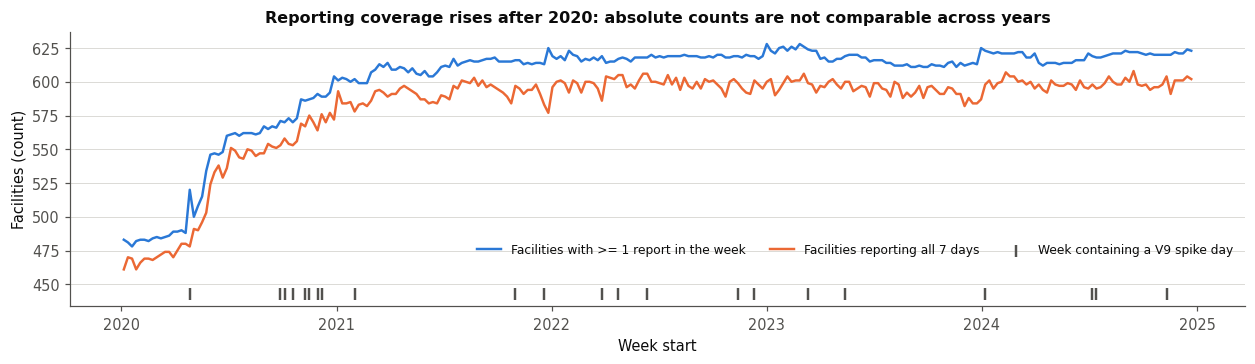

reporting_facilities             full_week_facilities            
                            min median  max                  min median  max
week_start                                                                  
2020                        478  560.0  604                  461  540.5  577
2021                        599  612.0  625                  577  591.5  603
2022                        614  618.0  623                  586  599.0  606
2023                        611  616.0  628                  582  596.0  606
2024                        612  621.0  624                  591  598.0  608

In [13]:
fac_week_days = fd.groupby(['week_start', 'IdEstablecimiento']).date.nunique()
coverage_week = fac_week_days.groupby('week_start').agg(
    reporting_facilities='size', full_week_facilities=lambda s: int(s.eq(7).sum()))
coverage_week = coverage_week.loc[coverage_week.index.isin(complete_weeks)]
fig, ax = plt.subplots(figsize=(11.5, 3.4))
ax.plot(coverage_week.index, coverage_week.reporting_facilities, color=SLOT[0], label='Facilities with >= 1 report in the week')
ax.plot(coverage_week.index, coverage_week.full_week_facilities, color=SLOT[1], label='Facilities reporting all 7 days')
spike_weeks = cw.loc[cw.spike_days.gt(0), 'week_start']
ax.scatter(spike_weeks, np.full(len(spike_weeks), coverage_week.full_week_facilities.min() - 18), marker='|',
           s=60, color=MUTED, label='Week containing a V9 spike day')
ax.set(title='Reporting coverage rises after 2020: absolute counts are not comparable across years',
       ylabel='Facilities (count)', xlabel='Week start')
ax.legend(ncol=3, loc='lower right', bbox_to_anchor=(1, .14), fontsize=8)
tidy(ax)
fig.tight_layout(); fig.savefig(FIG / 'fig4_reporting_coverage.png', bbox_inches='tight'); plt.show()
display(coverage_week.groupby(coverage_week.index.year).agg(['min', 'median', 'max']))

**Observation.** Weekly reporting coverage changed sharply *within* 2020. As few as 478 facilities reported in an early-2020 week, compared with a median of about 612-621 from 2021 onwards. Spike-day weeks are scattered across the period rather than concentrated in any one season.

**Implication.** C1 compared annual visit *volumes* (11.4 million in 2020 vs 19.4 million in 2024). Part of that gap is network coverage, not demand, so cross-year volume comparisons are **qualified**. The share KPI is less exposed because numerator and denominator come from the same reporting facilities, and C1's 581-facility panel gave nearly identical shares. It is not immune if newly reporting facilities have a different case mix.

**Balanced panel stability vs. epidemiological causation (Instructor Correction):** In C1, we highlighted that the 581-facility balanced panel (facilities active across all five years) matched the overall network's share trajectory almost perfectly (10.73% in 2020 to 28.37% in 2024, differing by $\le 0.14$ percentage points). As the instructor emphasized, this stability demonstrates **absence of facility entry/exit composition bias** (it proves the jump was not caused by newly reporting clinics), but **it does not demonstrate an epidemiological cause**. Administrative attendance records cannot separate true viral circulation increases from confounding factors like shifts in population care-seeking behavior (avoidance of health centers during 2020 lockdowns) or changes in clinical diagnostic coding thresholds.

### 3.6 Revised conclusions: W1/C1 statement → W2 status

| # | W1/C1 statement | W2 status | Evidence |
|---|---|---|---|
| 1 | Respiratory share ≈ 10% in 2020-2021 and 24.7-29.0% in 2022-2024 | **Retained**, now with validated robustness: excluding spike days moves it ≤ 0.008 pp | §2 V9, §3.1 |
| 2 | Annual volume grew from 11.4 M (2020) to 19.4 M (2024) | **Qualified**: weekly reporting facilities ramped from 478 to ≈ 600 during 2020; volumes are not like-for-like | Figure 4 |
| 3 | 2023 and 2024 complete-week peaks occurred in May | **Revised**: true for those two seasons, but 2022 peaked in Oct-Nov. The robust statement is "rise from March in recent seasons" | Figure 3 |
| 4 | Primary care and hospitals show "persistent operational coupling" (r = 0.98) | **Revised**: weekly co-movement remains (r = 0.93 on changes), but this is association with no shown mechanism; level r was inflated by shared seasonality (Instructor Feedback) | §3.3, Figure 2 |
| 5 | Age bands keep a "strongly monotonic severity hierarchy" (RSV vs influenza timing) | **Withdrawn**: change correlation <1 vs 65+ is 0.54, and the files contain no virology | Figure 2 |
| 6 | Pandemic-era low shares were "due to non-pharmacological interventions and school closures" | **Revised to unverified hypothesis**: no policy, stringency, or mobility variables in administrative data (Instructor Feedback) | §3 interpretations |
| 7 | Primary-care (SAPU+SAR+SUR) share of respiratory visits rose 71.1% → 75.9% | **Retained for the aggregate; SAR-specific growth mostly compositional** (19 reclassified facilities) | §3.4 table |
| 8 | W1 alert line at 30% share | **Replaced** by a rule learned on training weeks, chosen on validation and frozen before test (31.53%). Still illustrative, not an official standard | §6.5 |
| 9 | C1 claimed Pearson correlation requires bivariate normality | **Corrected**: Pearson's r as a sample descriptive statistic requires zero distributional assumptions; bivariate normality is needed only for inferential testing (Instructor Feedback) | §3.3 statistical note |
| 10 | C1 claimed 581-facility panel stability proved an epidemiological surge | **Clarified**: Panel stability rules out facility entry/exit composition bias, but does not prove epidemiological causation (Instructor Feedback) | §3.5, §4.1 |

## 4. Sampling and representativeness

### 4.1 Target, observed and analytical populations

| Population | Definition in this project |
|---|---|
| **Target population** | All emergency visits, and the respiratory subset, that Chile's public emergency network must absorb during 2020-2024. This is the demand Winter Campaign planners care about. |
| **Observed population** | Visits that were (a) made by people who sought emergency care, (b) recorded in a DAU at one of the 673 facility IDs that report to the DEIS emergency system (hospitals, SAPU, SAR, SUR, CEAR), and (c) coded as cause 1/2 and published in the 2020-2024 archives downloaded on 24 Sep 2026. |
| **Analytical dataset** | 1,084,911 de-duplicated facility-days with both causes (2,169,822 rows); weekly comparisons use 260 complete Sunday-Saturday weeks; holdout design uses 149,997 facility-week rows (§6). |

**How records were selected.** We drew no sample. The archives are an administrative census of what reporting facilities submitted. Selection happens upstream through who attends, which facilities report and on which days, and how visits are coded.

**Plausible sources of sampling or coverage bias.**
1. **Facility coverage and non-reporting.** Weekly reporting facilities rose from 478 to about 600 within 2020 (Figure 4). There are 23,200 absent facility-days (V8), and 27 IDs are missing from the 2022 register (V11). Demand at non-reporting facilities or on non-reported days is invisible.
2. **Care-seeking selection.** Only people who *attend* emergency care are counted. During 2020-2021 care seeking changed, so lower counts may partly mean fewer attendances rather than less illness.
3. **Scope of the network.** Facilities outside the DEIS emergency reporting system (for example private clinics that do not report to it) are not represented. The extent of this gap is not measurable from these files (**Assumption**).
4. **Measurement and coding.** Cause 2 depends on diagnostic coding in each facility. Visits are counted, not people, so repeat attendances by the same patient are counted more than once.

In [14]:
# Reproducible 25% subsample: stratified by source year x care-setting type, unit = facility-date pair
sample = (fd.groupby(['source_year', 'type'], group_keys=False)
            .sample(frac=0.25, random_state=SEED))
assert sample.index.is_unique and abs(len(sample) - 0.25 * len(fd)) < 20
sample_again = fd.groupby(['source_year', 'type'], group_keys=False).sample(frac=0.25, random_state=SEED)
assert sample.index.equals(sample_again.index), 'Sample is not reproducible'
sample[['IdEstablecimiento', 'date']].to_csv(OUT / 'sample25_keys.csv.gz', index=False)

def kpis(frame):
    under15 = frame[['Menores_1', 'De_1_a_4', 'De_5_a_14']].sum().sum()
    return pd.Series({
        'facility_dates': len(frame),
        'KPI respiratory share (%)': 100 * frame.resp_visits.sum() / frame.all_visits.sum(),
        'KPI 2024 respiratory share (%)': 100 * frame.loc[frame.source_year.eq(2024), 'resp_visits'].sum()
                                          / frame.loc[frame.source_year.eq(2024), 'all_visits'].sum(),
        'Segment: primary care % of respiratory visits': 100 * frame.loc[frame.type.isin(['SAPU', 'SAR', 'SUR']), 'resp_visits'].sum() / frame.resp_visits.sum(),
        'Segment: under-15 % of respiratory visits': 100 * under15 / frame.resp_visits.sum(),
        'Segment: SUR % of facility-dates': 100 * frame.type.eq('SUR').mean(),
    })

comparison = pd.DataFrame({'full_analytical_dataset': kpis(fd), 'stratified_25pct_sample': kpis(sample)})
comparison['difference'] = comparison.stratified_25pct_sample - comparison.full_analytical_dataset
comparison.round(3).to_csv(OUT / 'sampling_comparison.csv')
display(comparison.round(3))
log_rows('6 stratified 25% sample', sample, f'seed {SEED}; strata = year x type')

,full_analytical_dataset,stratified_25pct_sample,difference
facility_dates,1084911.000,271227.000,-813684.000
KPI respiratory share (%),22.214,22.258,0.044
KPI 2024 respiratory share (%),28.512,28.574,0.061
Segment: primary care % of respiratory visits,73.864,73.702,-0.162
Segment: under-15 % of respiratory visits,44.326,44.387,0.062
Segment: SUR % of facility-dates,18.478,18.479,0.000


,design,mean_estimate,sd_estimate,p2_5,p97_5
0,25% of facility-dates (simple random),22.211,0.033,22.152,22.275
1,25% of facilities (cluster),22.324,0.729,20.857,23.708


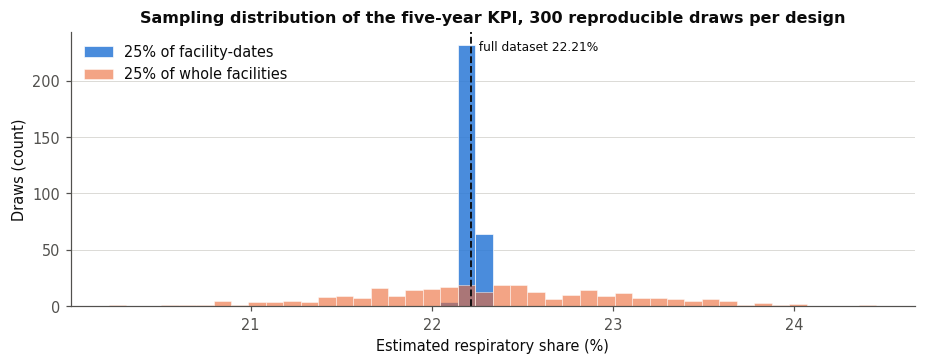

In [15]:
# Sampling variability: 300 repeated 25% samples under two designs (seeds SEED..SEED+299)
fac_year = fd.groupby(['IdEstablecimiento', 'type'])[['all_visits', 'resp_visits']].sum().reset_index()
fac_list = fd[['IdEstablecimiento']].drop_duplicates()
row_est, cluster_est = [], []
for i in range(300):
    s = fd[['all_visits', 'resp_visits']].sample(frac=.25, random_state=SEED + i)
    row_est.append(100 * s.resp_visits.sum() / s.all_visits.sum())
    chosen = fac_list.sample(frac=.25, random_state=SEED + i).IdEstablecimiento
    c = fac_year.loc[fac_year.IdEstablecimiento.isin(chosen)]
    cluster_est.append(100 * c.resp_visits.sum() / c.all_visits.sum())
variability = pd.DataFrame({'design': ['25% of facility-dates (simple random)', '25% of facilities (cluster)'],
                            'mean_estimate': [np.mean(row_est), np.mean(cluster_est)],
                            'sd_estimate': [np.std(row_est, ddof=1), np.std(cluster_est, ddof=1)],
                            'p2_5': [np.percentile(row_est, 2.5), np.percentile(cluster_est, 2.5)],
                            'p97_5': [np.percentile(row_est, 97.5), np.percentile(cluster_est, 97.5)]})
display(variability.round(3))

fig, ax = plt.subplots(figsize=(8.5, 3.4))
bins = np.linspace(min(cluster_est + row_est), max(cluster_est + row_est), 45)
ax.hist(row_est, bins=bins, color=SLOT[0], alpha=.85, label='25% of facility-dates', edgecolor='white', lw=.5)
ax.hist(cluster_est, bins=bins, color=SLOT[1], alpha=.6, label='25% of whole facilities', edgecolor='white', lw=.5)
ax.axvline(pooled_all, color=INK, lw=1.2, ls='--')
ax.text(pooled_all, ax.get_ylim()[1] * .93, f'  full dataset {pooled_all:.2f}%', fontsize=8)
ax.set(title='Sampling distribution of the five-year KPI, 300 reproducible draws per design',
       xlabel='Estimated respiratory share (%)', ylabel='Draws (count)')
ax.legend(loc='upper left'); tidy(ax)
fig.tight_layout(); fig.savefig(FIG / 'fig5_sampling_variability.png', bbox_inches='tight'); plt.show()

**Observation.** The reproducible 25% stratified sample (271,227 facility-days; strata = year × care-setting type; `SEED = 2026`; keys saved to `sample25_keys.csv.gz`) reproduces the KPI within 0.044 points overall and 0.061 points for 2024. It reproduces the segment proportions within 0.16 points (primary-care share), 0.06 points (under-15 share) and 0.000 points (SUR share of facility-days, guaranteed by stratification).

**The sampling unit matters.** Figure 5 repeats each design 300 times. Sampling 25% of facility-days gives a standard deviation of 0.033 points. Sampling 25% of *whole facilities* gives 0.729 points, about 22 times larger (95% of draws between 20.86% and 23.71%), because facilities differ systematically (Figure 1). Facility identity is therefore the natural cluster, which is why §5 treats repeated facilities as a leakage risk.

**Why a good sample, or a train/test split, does not prove representativeness.** Both are drawn from the *observed* population. A random or stratified sample only shows that our subset resembles the dataset. A train/test split only partitions that same dataset. Neither can reveal visits that never entered it: non-reporting facilities, non-reported days, people who did not attend, and facilities outside the reporting system. Agreement between train and test therefore shows *internal consistency*, not that the source data represent Chile's emergency demand. Our split is chronological, so train and test are intentionally *not* exchangeable (training mean target 82 visits per facility-week vs 175 in test).

## 5. Leakage audit

### 5.1 Decision time and data flow

**Is a predictive use legitimate?** The W1/C1 project is **descriptive**, and W2 fits no model. C1 proposed one future use: a **two-week-ahead forecast of weekly respiratory visits** to time Winter Campaign reviews. We assess its legitimacy here and build the holdout for that use (§6), without inventing a fitted model.

**Data flow.** Patient attends → DAU record at the facility → daily facility × cause aggregate published by DEIS (the dictionary states daily updates) → national weekly KPI.

**Decision time.** Planners meet after week *t* closes (Saturday) and decide whether to intensify review for weeks *t+1* and *t+2*. **Assumption:** complete counts for week *t* are available at that meeting. This is not verifiable from a single 2026 download (L7).

| Available at decision time | Not available at decision time |
|---|---|
| Daily/weekly counts for completed weeks ≤ *t* (visits, respiratory visits, age bands, reporting days) | Any count from weeks *t+1*, *t+2* (including all-visit totals, which contain the target) |
| Facility type as recorded at week *t* | Facility type after later reclassification; register versions dated after *t* |
| Calendar position of the target week (deterministic) | Annual totals of the current year; facility presence in later years (the 581 "common" panel) |
| Thresholds learned on earlier weeks | Final, revised archive values (late corrections; L7) |

**Verdict.** A forecasting use is legitimate *only* with lagged inputs, a reliable weekly feed and the controls below. The audit applies the same reasoning to descriptive outputs, such as an alert threshold.

In [16]:
# Evidence for the leakage audit (computed, not asserted)
ev = {}
# L1 - the all-visit denominator contains the target
nat = cw.set_index('week_start')
ev['L1_corr'] = nat.resp_visits.corr(nat.all_visits)
ev['L1_share_of_all'] = 100 * nat.resp_visits.sum() / nat.all_visits.sum()
# L2 - hindsight panel: facilities whose 'present all five years' status depends on 2024
present = fd.groupby('IdEstablecimiento').source_year.agg(lambda s: set(s))
in_2020_23 = present.apply(lambda s: {2020, 2021, 2022, 2023} <= s)
ev['L2_needs_2024'] = int((in_2020_23 & ~present.apply(lambda s: 2024 in s)).sum())
ev['L2_panel'] = int(present.apply(lambda s: s == {2020, 2021, 2022, 2023, 2024}).sum())
# L3 - duplicates
ev['L3_dups'] = extra
# L4 - repeated facilities and autocorrelation under a naive random split of facility-weeks
fw_tmp = fd.loc[fd.week_start.isin(complete_weeks)].groupby(['IdEstablecimiento', 'week_start']).resp_visits.sum()
ac = fw_tmp.groupby(level=0).apply(lambda s: s.droplevel(0).sort_index().autocorr(1) if len(s) > 10 else np.nan)
ev['L4_median_autocorr'] = float(ac.median())
naive = fw_tmp.reset_index()
naive['test'] = np.random.default_rng(SEED).random(len(naive)) < .2
prev = (naive[['IdEstablecimiento', 'week_start', 'test']].rename(columns={'test': 'prev_week_test'})
        .assign(week_start=lambda d: d.week_start + pd.Timedelta(days=7)))
naive_test = naive.loc[naive.test].merge(prev, on=['IdEstablecimiento', 'week_start'], how='left')
ev['L4_pct_test_with_prev_week_in_train'] = 100 * naive_test.prev_week_test.eq(False).mean()
ev['L4_facilities_in_both'] = int(naive.groupby('IdEstablecimiento').test.nunique().eq(2).sum())
# L5 - linked/derived attributes: latest facility type applied backwards
latest_type = fd.sort_values('date').groupby('IdEstablecimiento').type.last()
ev['L5_rows_type_differs_latest'] = int(fd.type.ne(fd.IdEstablecimiento.map(latest_type)).sum())
ev['L5_register_unmatched'] = len(unmatched)
# L6 - preprocessing learned on the full period (V9 medians, W1 threshold)
ev['L6_spike_flags'] = int(fd.spike_flag.sum())
med_pre = fd.loc[fd.all_visits.gt(0) & fd.source_year.le(2022)].groupby('IdEstablecimiento').all_visits.median()
ev['L6_median_shift'] = float((nonzero_median.reindex(med_pre.index) - med_pre).abs().median())
for k, v in ev.items():
    print(f'{k:40s} {v:,.3f}' if isinstance(v, float) else f'{k:40s} {v:,}')

/var/data/python/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


L1_corr                                  0.881
L1_share_of_all                          22.233
L2_needs_2024                            9
L2_panel                                 581
L3_dups                                  2
L4_median_autocorr                       0.924
L4_pct_test_with_prev_week_in_train      79.262
L4_facilities_in_both                    665
L5_rows_type_differs_latest              12,687
L5_register_unmatched                    27
L6_spike_flags                           45
L6_median_shift                          7.000


In [17]:
audit = pd.DataFrame([
    ['L1 Target-derived variables', 'Present',
     f"ID 1 (all visits) includes ID 2: respiratory visits are {ev['L1_share_of_all']:.1f}% of all visits; weekly r = {ev['L1_corr']:.2f}. The KPI share for week t+2 is a function of the target.",
     'A feature such as all visits or share in the target week would reproduce the target and inflate accuracy.',
     'Exclude every target-week quantity (all visits, share, age bands, spike flags). Use only weeks <= t. Asserted in §6.'],
    ['L2 Future information (hindsight panels, centred windows)', 'Present (C1 descriptive panel)',
     f"C1's {ev['L2_panel']}-facility common panel requires knowing 2024 presence; {ev['L2_needs_2024']} facilities active 2020-2023 are excluded only because of 2024. Centred moving averages would also use t+1.",
     'A model trained on survivors would look better than it would in real time (survivorship bias).',
     'No panel membership, annual totals or centred windows as features; only trailing windows ending at t.'],
    ['L3 Duplicated records', 'Present in raw, removed',
     f"{ev['L3_dups']} identical extra rows (facility 08-105, 10 Jan 2023). Under a random split, a copy could fall in train and its twin in test.",
     'Memorised rows score perfectly in test, with no generalisation.',
     'De-duplicate before any split (V3); assert unique (facility, origin week) keys and no key in two splits.'],
    ['L4 Repeated facilities and temporal autocorrelation', 'Present',
     f"Median lag-1 autocorrelation of facility weekly respiratory visits = {ev['L4_median_autocorr']:.2f}. In a naive 80/20 random split of facility-weeks, {ev['L4_pct_test_with_prev_week_in_train']:.0f}% of test rows have the same facility's previous week in train; {ev['L4_facilities_in_both']} facilities fall in both splits.",
     'Test performance would measure interpolation between neighbouring weeks, not forecasting a future season.',
     'Chronological split by target week (§6). Facilities intentionally appear in all periods because the decision forecasts the same network; new facilities in test are counted.'],
    ['L5 Linked tables and slowly changing attributes', 'Present (type), uncertain (register)',
     f"{ev['L5_rows_type_differs_latest']:,} facility-dates have a type different from the facility's latest type (19 reclassified facilities). The only register available is dated 08-07-2022; {ev['L5_register_unmatched']} IDs are unmatched.",
     'Back-filling the 2024 type, or a 2022 register, into 2020-2021 rows uses information not available then.',
     'Use the type recorded at week t. No register join; any future join must use a register vintage <= origin date.'],
    ['L6 Preprocessing learned on all data', 'Present in W1/C1, mitigated in W2',
     f"V9 spike rule uses each facility's five-year median ({ev['L6_spike_flags']} flags); the median moves by {ev['L6_median_shift']:.1f} visits/day (median facility) when only 2020-2022 is used. W1's 30% alert line was chosen after viewing all years.",
     'Scaling, imputation or thresholds tuned on test weeks leak their distribution into training.',
     'Spike flags are not model features. Imputer, scaler, encoder and alert threshold are fitted on training rows only (§6.5-6.6).'],
    ['L7 Data vintage and late revisions', 'Uncertain',
     'Archives were downloaded on 24 Sep 2026, long after the events. DEIS updates daily, but we have only one vintage, so we cannot measure how week t counts looked at the time.',
     'Back-filled final counts are more complete than real-time counts; historical evaluation would be optimistic.',
     'Treat as a limitation; archive weekly snapshots before any operational use; add a reporting-lag scenario.'],
    ['L8 Test-period exposure in W1/C1 EDA', 'Present',
     'C1 reported 2024 peak weeks (12-18 May 2024, 45.56%) and annual 2024 shares before this split existed.',
     'Choices (e.g. calendar features, the May framing) may already be shaped by 2024.',
     'Declare the 2024 holdout as "previously explored"; freeze features before any test use; use it only once, as a robustness check.'],
], columns=['risk', 'status', 'dataset evidence', 'potential consequence', 'mitigation'])
audit.to_csv(OUT / 'leakage_audit.csv', index=False)
display(HTML(audit.to_html(index=False, justify='left')))

risk,status,dataset evidence,potential consequence,mitigation
L1 Target-derived variables,Present,ID 1 (all visits) includes ID 2: respiratory visits are 22.2% of all visits; weekly r = 0.88. The KPI share for week t+2 is a function of the target.,A feature such as all visits or share in the target week would reproduce the target and inflate accuracy.,"Exclude every target-week quantity (all visits, share, age bands, spike flags). Use only weeks <= t. Asserted in §6."
"L2 Future information (hindsight panels, centred windows)",Present (C1 descriptive panel),C1's 581-facility common panel requires knowing 2024 presence; 9 facilities active 2020-2023 are excluded only because of 2024. Centred moving averages would also use t+1.,A model trained on survivors would look better than it would in real time (survivorship bias).,"No panel membership, annual totals or centred windows as features; only trailing windows ending at t."
L3 Duplicated records,"Present in raw, removed","2 identical extra rows (facility 08-105, 10 Jan 2023). Under a random split, a copy could fall in train and its twin in test.","Memorised rows score perfectly in test, with no generalisation.","De-duplicate before any split (V3); assert unique (facility, origin week) keys and no key in two splits."
L4 Repeated facilities and temporal autocorrelation,Present,"Median lag-1 autocorrelation of facility weekly respiratory visits = 0.92. In a naive 80/20 random split of facility-weeks, 79% of test rows have the same facility's previous week in train; 665 facilities fall in both splits.","Test performance would measure interpolation between neighbouring weeks, not forecasting a future season.",Chronological split by target week (§6). Facilities intentionally appear in all periods because the decision forecasts the same network; new facilities in test are counted.
L5 Linked tables and slowly changing attributes,"Present (type), uncertain (register)","12,687 facility-dates have a type different from the facility's latest type (19 reclassified facilities). The only register available is dated 08-07-2022; 27 IDs are unmatched.","Back-filling the 2024 type, or a 2022 register, into 2020-2021 rows uses information not available then.",Use the type recorded at week t. No register join; any future join must use a register vintage <= origin date.
L6 Preprocessing learned on all data,"Present in W1/C1, mitigated in W2",V9 spike rule uses each facility's five-year median (45 flags); the median moves by 7.0 visits/day (median facility) when only 2020-2022 is used. W1's 30% alert line was chosen after viewing all years.,"Scaling, imputation or thresholds tuned on test weeks leak their distribution into training.","Spike flags are not model features. Imputer, scaler, encoder and alert threshold are fitted on training rows only (§6.5-6.6)."
L7 Data vintage and late revisions,Uncertain,"Archives were downloaded on 24 Sep 2026, long after the events. DEIS updates daily, but we have only one vintage, so we cannot measure how week t counts looked at the time.",Back-filled final counts are more complete than real-time counts; historical evaluation would be optimistic.,Treat as a limitation; archive weekly snapshots before any operational use; add a reporting-lag scenario.
L8 Test-period exposure in W1/C1 EDA,Present,"C1 reported 2024 peak weeks (12-18 May 2024, 45.56%) and annual 2024 shares before this split existed.","Choices (e.g. calendar features, the May framing) may already be shaped by 2024.","Declare the 2024 holdout as ""previously explored""; freeze features before any test use; use it only once, as a robustness check."


**Reading the audit.** Six risks are *present* in the data and two are *uncertain*. None is a generic "not applicable": each status rests on evidence computed above. The two that would most distort a future evaluation are **L4** (a naive random split puts the same facility's previous week in training for 79% of test rows, with lag-1 autocorrelation 0.92) and **L1** (the all-visit denominator contains the target). The design in §6 removes both by construction, and asserts in code check that it does. **L7** cannot be removed with one data vintage and remains the main limitation for any real-time claim.

## 6. Train/validation/test datasets and validation plan

### 6.1 Split choice

**Chosen design: chronological split by target week, in whole years.** Each row is a facility × origin week *t*. Features come only from weeks ≤ *t*, and the target is the facility's respiratory visits in week *t+2*. Rows are assigned to a split by the year of the **target week's ending Saturday** (C1's `reporting_year`): train = 2020-2022, validation = 2023, test = 2024.

| Consideration | Implication for the split |
|---|---|
| **Business process** | Planners forecast *future* weeks for the *same* network, so the test must lie after the training data in time. |
| **Time ordering** | Weekly counts are strongly autocorrelated (L4), so random or stratified row splits would leak neighbouring weeks. |
| **Target** | A count with strong seasonality. Whole-year blocks give validation and test one complete winter season each, whereas a 20% block cut mid-year would split a season. |
| **Repeated observations** | Facilities recur by design (deployment population = the same network). A facility-grouped split would answer a different question (forecasting *new* facilities). We instead **report** facility overlap and the 10 cold-start facilities that first appear in 2024. |
| **Regime change** | 2020-2021 is a pandemic regime. It is kept in training, and the validation block is where its effect is tested (§6.5) rather than judged by eye. |

The resulting proportions are 58.6% / 20.6% / 20.7% of rows (154 / 52 / 52 target weeks). This is close to 60/20/20 because whole seasons, not an 80/20 rule, set the boundaries.

In [18]:
# Facility x week panel on a full calendar grid, so lags are true calendar lags (absent weeks stay missing)
fw = (fd.groupby(['IdEstablecimiento', 'week_start'])
        .agg(resp=('resp_visits', 'sum'), all=('all_visits', 'sum'), reporting_days=('date', 'nunique'),
             type=('type', 'last'))
        .reset_index())
fw = fw.loc[fw.week_start.isin(complete_weeks)]
grid = pd.MultiIndex.from_product([sorted(fw.IdEstablecimiento.unique()), sorted(complete_weeks)],
                                  names=['IdEstablecimiento', 'week_start'])
panel = fw.set_index(['IdEstablecimiento', 'week_start']).reindex(grid).reset_index()
panel['reporting_days'] = panel.reporting_days.fillna(0).astype(int)
g = panel.groupby('IdEstablecimiento', group_keys=False)
HORIZON = 2  # forecast week t+2 from information available at the end of week t
panel['target_resp'] = g.resp.shift(-HORIZON)
panel['target_week_start'] = g.week_start.shift(-HORIZON)
panel['target_reporting_days'] = g.reporting_days.shift(-HORIZON)
panel['resp_lag0'] = panel.resp
panel['resp_lag1'] = g.resp.shift(1)
panel['resp_lag2'] = g.resp.shift(2)
panel['resp_mean4'] = g.resp.transform(lambda s: s.rolling(4, min_periods=1).mean())   # trailing only
panel['nonresp_lag0'] = panel['all'] - panel.resp
panel['share_lag0'] = panel.resp / panel['all'].replace(0, np.nan)
panel['type_at_t'] = g.type.ffill()                                                   # last known type at t
panel['ever_reported_by_t'] = g.reporting_days.cumsum().gt(0)

# Keep rows where the facility is known at t and the target week was fully reported
model = panel.loc[panel.ever_reported_by_t & panel.target_reporting_days.eq(7)].copy()
model = model.rename(columns={'week_start': 'origin_week_start'})
assert model.type_at_t.notna().all()
model['type_at_t'] = model.type_at_t.astype(str)
# Calendar position of the target week is known in advance (deterministic), so it is a legitimate input
target_iso_week = (model.target_week_start + pd.Timedelta(days=3)).dt.isocalendar().week.astype(int)
model['target_week_sin'] = np.sin(2 * np.pi * target_iso_week / 52.18)
model['target_week_cos'] = np.cos(2 * np.pi * target_iso_week / 52.18)
model['target_year'] = (model.target_week_start + pd.Timedelta(days=6)).dt.year
FEATURES_NUM = ['resp_lag0', 'resp_lag1', 'resp_lag2', 'resp_mean4', 'nonresp_lag0', 'share_lag0', 'reporting_days']
FEATURES_CAT = ['type_at_t']
FEATURES_CAL = ['target_week_sin', 'target_week_cos']
COLUMNS = ['IdEstablecimiento', 'origin_week_start', 'target_week_start', 'target_year', 'target_resp',
           *FEATURES_NUM, *FEATURES_CAT, *FEATURES_CAL]
model = model[COLUMNS].reset_index(drop=True)
log_rows('7 facility-week grid', panel, f"{panel.IdEstablecimiento.nunique()} facilities x 260 complete weeks")
log_rows('8 modelling table', model, 'facility known at t; target week fully reported')
print(f'Modelling rows: {len(model):,}; facilities: {model.IdEstablecimiento.nunique()}; '
      f'target weeks: {model.target_week_start.nunique()}')
print('Missing feature cells (before imputation):'); display(model[FEATURES_NUM + FEATURES_CAT].isna().sum().to_frame('missing').T)

# Leakage guard: every feature is dated at or before origin week t, which is HORIZON weeks before the target
assert (model.target_week_start - model.origin_week_start).eq(pd.Timedelta(weeks=HORIZON)).all()
assert not set(model.columns) & {'all', 'resp', 'type', 'share_target', 'spike_flag'}

Modelling rows: 149,997; facilities: 663; target weeks: 258
Missing feature cells (before imputation):


,resp_lag0,resp_lag1,resp_lag2,resp_mean4,nonresp_lag0,share_lag0,reporting_days,type_at_t
missing,160,871,1564,88,160,1581,0,0


In [19]:
# 6.2 Chronological split by TARGET week: train <= 2022, validation = 2023, test = 2024
period = np.select([model.target_year.le(2022), model.target_year.eq(2023), model.target_year.eq(2024)],
                   ['train', 'validation', 'test'], default='unassigned')
model['split'] = period
assert model.split.ne('unassigned').all()
train, val, test = (model.loc[model.split.eq(s)] for s in ['train', 'validation', 'test'])
dev = model.loc[model.split.isin(['train', 'validation'])]

summary = model.groupby('split', sort=False).agg(
    rows=('target_resp', 'size'), facilities=('IdEstablecimiento', 'nunique'),
    target_weeks=('target_week_start', 'nunique'), first_target_week=('target_week_start', 'min'),
    last_target_week=('target_week_start', 'max'), mean_target=('target_resp', 'mean')).reindex(['train', 'validation', 'test'])
summary['row_pct'] = 100 * summary.rows / summary.rows.sum()
summary['week_pct'] = 100 * summary.target_weeks / summary.target_weeks.sum()
summary.to_csv(OUT / 'split_manifest.csv')
display(summary.round({'mean_target': 2, 'row_pct': 2, 'week_pct': 2}))

# Overlap and ordering checks
key = ['IdEstablecimiento', 'origin_week_start']
assert model.duplicated(key).sum() == 0
for a, b in [('train', 'validation'), ('train', 'test'), ('validation', 'test')]:
    A, B = model.loc[model.split.eq(a)], model.loc[model.split.eq(b)]
    assert not set(A.target_week_start) & set(B.target_week_start), f'{a}/{b} share target weeks'
    assert A.merge(B, on=key).empty, f'{a}/{b} share row keys'
assert train.target_week_start.max() < val.target_week_start.min() <= val.target_week_start.max() < test.target_week_start.min()
# No training row uses information dated in the validation or test period
assert train.origin_week_start.max() < val.target_week_start.min()
assert dev.origin_week_start.max() < test.target_week_start.min()
new_in_test = sorted(set(test.IdEstablecimiento) - set(dev.IdEstablecimiento))
print('Checks passed: unique keys, disjoint target weeks, strict time order, features dated before each target period.')
print(f'Facilities in test never seen in train/validation (cold start): {len(new_in_test)}')
for name, frame in [('train', train), ('validation', val), ('test', test)]:
    frame.drop(columns='split').to_csv(SPLITS / f'{name}.csv.gz', index=False)
log_rows('9a train', train, 'targets in 2020-2022')
log_rows('9b validation', val, 'targets in 2023')
log_rows('9c test', test, 'targets in 2024 (previously explored in W1/C1)')

,rows,facilities,target_weeks,first_target_week,last_target_week,mean_target,row_pct,week_pct
split,,,,,,,,
train,87937,646,154,2020-01-19,2022-12-25,82.02,58.63,59.69
validation,30939,631,52,2023-01-01,2023-12-24,176.83,20.63,20.16
test,31121,633,52,2023-12-31,2024-12-22,175.06,20.75,20.16


Checks passed: unique keys, disjoint target weeks, strict time order, features dated before each target period.
Facilities in test never seen in train/validation (cold start): 10


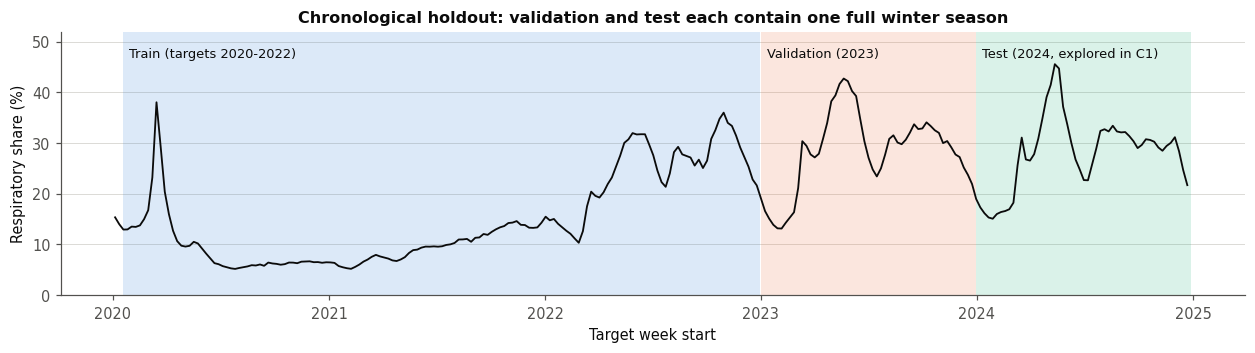

In [20]:
# Figure 6 - the split on the national KPI timeline
fig, ax = plt.subplots(figsize=(11.5, 3.3))
ax.plot(cw.week_start, cw.resp_share_pct, color=INK, lw=1.2)
for (name, frame), color in zip([('Train (targets 2020-2022)', train), ('Validation (2023)', val),
                                 ('Test (2024, explored in C1)', test)], SLOT[:3]):
    ax.axvspan(frame.target_week_start.min(), frame.target_week_start.max() + pd.Timedelta(days=6),
               color=color, alpha=.16, lw=0)
    ax.text(frame.target_week_start.min() + pd.Timedelta(days=10), 47, name, fontsize=8.5, color=INK)
ax.set(title='Chronological holdout: validation and test each contain one full winter season',
       ylabel='Respiratory share (%)', xlabel='Target week start', ylim=(0, 52))
tidy(ax)
fig.tight_layout(); fig.savefig(FIG / 'fig6_chronological_split.png', bbox_inches='tight'); plt.show()

### 6.3 Internal validation: separate validation block and rolling-origin cross-validation inside the development data

* **Separate validation block (2023 targets)** for comparing candidate rules, features or future models. The test block is not used.
* **Rolling-origin cross-validation inside development data only** (fold 1: fit 2020-2021 → assess 2022; fold 2: fit 2020-2022 → assess 2023). This checks whether a choice is stable across two different seasons, including one (2022) whose peak came in October-November.
* **No embargo gap is needed.** The split is defined on the *target* week and every feature is dated at *t* = target − 2 weeks, so no training row can contain information from the validation or test period (asserted). Validation rows do use training-period weeks as lags, which is legitimate: those weeks are in the past at decision time.
* **Test (2024)** is used once, only after features, preprocessing and rules are frozen.

In [21]:
# Rolling-origin (expanding window) folds restricted to development data (train + validation); test excluded
folds = [('fold 1', [2020, 2021], 2022), ('fold 2', [2020, 2021, 2022], 2023)]
fold_rows = []
test_index = set(test.index)
for name, fit_years, assess_year in folds:
    fit_idx = dev.index[dev.target_year.isin(fit_years)]
    assess_idx = dev.index[dev.target_year.eq(assess_year)]
    assert not (set(fit_idx) | set(assess_idx)) & test_index
    assert model.loc[fit_idx, 'origin_week_start'].max() < model.loc[assess_idx, 'target_week_start'].min()
    fold_rows.append({'fold': name, 'fit_target_years': f'{fit_years[0]}-{fit_years[-1]}', 'assess_target_year': assess_year,
                      'fit_rows': len(fit_idx), 'assess_rows': len(assess_idx),
                      'fit_last_target': model.loc[fit_idx, 'target_week_start'].max().date(),
                      'assess_first_target': model.loc[assess_idx, 'target_week_start'].min().date(),
                      'overlap_rows': len(set(fit_idx) & set(assess_idx))})
cv_table = pd.DataFrame(fold_rows)
cv_table.to_csv(OUT / 'cv_folds.csv', index=False)
display(cv_table)

,fold,fit_target_years,assess_target_year,fit_rows,assess_rows,fit_last_target,assess_first_target,overlap_rows
0,fold 1,2020-2021,2022,56241,31696,2021-12-19,2021-12-26,0
1,fold 2,2020-2022,2023,87937,30939,2022-12-25,2023-01-01,0


### 6.4 Preprocessing learned from training data only

The same `ColumnTransformer` is used in every step: median imputation of missing lags (facility absent that week), `log1p`, standardisation and one-hot encoding of care-setting type. A guard function refuses to fit on any row from the test period.

In [22]:
def make_preprocessor():
    numeric = make_pipeline(SimpleImputer(strategy='median'),
                            FunctionTransformer(np.log1p, feature_names_out='one-to-one'), StandardScaler())
    categorical = make_pipeline(SimpleImputer(strategy='most_frequent'),
                                OneHotEncoder(handle_unknown='ignore', sparse_output=False))
    return ColumnTransformer([('num', numeric, FEATURES_NUM), ('cat', categorical, FEATURES_CAT),
                              ('cal', 'passthrough', FEATURES_CAL)])

def fit_guarded(frame):
    assert not frame.index.isin(test.index).any(), 'Refusing to fit preprocessing on test rows'
    return make_preprocessor().fit(frame[FEATURES_NUM + FEATURES_CAT + FEATURES_CAL])

X = lambda frame: frame[FEATURES_NUM + FEATURES_CAT + FEATURES_CAL]
prep_train = fit_guarded(train)                 # used to transform validation
Xt_train, Xt_val = prep_train.transform(X(train)), prep_train.transform(X(val))

num = prep_train.named_transformers_['num']
learned = pd.DataFrame({'imputer_median (raw units)': num.named_steps['simpleimputer'].statistics_,
                        'scaler_mean (log1p units)': num.named_steps['standardscaler'].mean_,
                        'scaler_sd (log1p units)': num.named_steps['standardscaler'].scale_},
                       index=FEATURES_NUM)
print('Categories learned from training rows:', list(prep_train.named_transformers_['cat'].named_steps['onehotencoder'].categories_[0]))
display(learned.round(4))

# Verify that validation was transformed with TRAINING parameters (no refit)
col = 'resp_lag1'; j = FEATURES_NUM.index(col)
manual = (np.log1p(val[col].fillna(learned.loc[col, 'imputer_median (raw units)'])) - learned.loc[col, 'scaler_mean (log1p units)']) / learned.loc[col, 'scaler_sd (log1p units)']
assert np.allclose(manual.to_numpy(), Xt_val[:, j])
print(f'Validation column {col!r} equals (log1p(imputed) - train mean) / train sd: verified for {len(val):,} rows.')
print(f'Training-transformed means are ~0 by construction: {Xt_train[:, :len(FEATURES_NUM)].mean(axis=0).round(3)}')
print(f'Validation-transformed means are not forced to 0: {Xt_val[:, :len(FEATURES_NUM)].mean(axis=0).round(3)}')

Categories learned from training rows: ['CEAR', 'Hospital', 'SAPU', 'SAR', 'SUR']


,imputer_median (raw units),scaler_mean (log1p units),scaler_sd (log1p units)
resp_lag0,40.0000,3.5734,1.4749
resp_lag1,39.0000,3.5674,1.4692
resp_lag2,39.0000,3.5612,1.4619
resp_mean4,40.2500,3.6068,1.4193
nonresp_lag0,325.0000,5.5825,1.1726
share_lag0,0.1135,0.1366,0.1079
reporting_days,7.0000,2.0721,0.0886


Validation column 'resp_lag1' equals (log1p(imputed) - train mean) / train sd: verified for 30,939 rows.
Training-transformed means are ~0 by construction: [ 0. -0.  0. -0. -0. -0. -0.]
Validation-transformed means are not forced to 0: [0.748 0.753 0.76  0.769 0.039 1.097 0.004]


In [23]:
# Final step before any test use: refit on development rows (train + validation) only, then transform test once
prep_dev = fit_guarded(dev)
Xt_test = prep_dev.transform(X(test))
try:
    fit_guarded(test)
except AssertionError as err:
    print('Guard works:', err)

dev_params = prep_dev.named_transformers_['num'].named_steps['standardscaler'].mean_
# Illustration only - what a leaky full-data fit would have learned (never used downstream)
leaky = make_preprocessor().fit(X(model)).named_transformers_['num'].named_steps['standardscaler'].mean_
param_compare = pd.DataFrame({'fit_on_train': learned['scaler_mean (log1p units)'], 'fit_on_dev': dev_params,
                              'fit_on_all_rows_LEAKY_not_used': leaky}, index=FEATURES_NUM)
param_compare['leak_shift_vs_dev'] = param_compare.fit_on_all_rows_LEAKY_not_used - param_compare.fit_on_dev
param_compare.round(4).to_csv(OUT / 'preprocessing_parameters.csv')
display(param_compare.round(4))
print('Test matrix shape:', Xt_test.shape, '| no model is fitted and no test metric is computed in W2.')

Guard works: Refusing to fit preprocessing on test rows


,fit_on_train,fit_on_dev,fit_on_all_rows_LEAKY_not_used,leak_shift_vs_dev
resp_lag0,3.5734,3.8609,4.0339,0.1730
resp_lag1,3.5674,3.8581,4.0320,0.1740
resp_lag2,3.5612,3.8549,4.0297,0.1748
resp_mean4,3.6068,3.8911,4.0617,0.1707
nonresp_lag0,5.5825,5.5945,5.6058,0.0114
share_lag0,0.1366,0.1678,0.1858,0.0180
reporting_days,2.0721,2.0722,2.0724,0.0002


Test matrix shape: (31121, 14) | no model is fitted and no test metric is computed in W2.


### 6.5 Treatment of test information and a descriptive robustness check

**Rules applied to the test block.** (1) Test rows never enter a `fit` (guard function above). (2) Variables, cleaning thresholds (V9) and the alert rule were fixed using training/validation weeks only. (3) The test block is evaluated once and the result is reported whatever it shows. (4) **Honest limitation:** 2024 is *not untouched*. W1 and C1 explored the full 2020-2024 data, including the 2024 May peak, so this holdout is an **independent robustness check of a frozen rule**, not an unbiased measure of predictive accuracy.

**Robustness check.** Because the project is descriptive, we test the planning rule C1 implies: "intensify review when the weekly share is high". The procedure is (a) fit two candidate thresholds on training weeks only, (b) choose between them on validation with a criterion stated *before* looking (must flag the validation peak; fewest alert weeks), (c) refit the chosen rule on development weeks, and (d) apply it once to 2024.

In [24]:
# Alert-threshold rule: learned on training weeks, compared on validation, refitted on development, applied ONCE to test
nat_week = cw.set_index('week_start').resp_share_pct
week_year = lambda weeks: pd.Index(weeks) + pd.Timedelta(days=6)
train_weeks = sorted(set(train.target_week_start))
val_weeks, test_weeks = sorted(set(val.target_week_start)), sorted(set(test.target_week_start))
post_train_weeks = [w for w, e in zip(train_weeks, week_year(train_weeks)) if e.year == 2022]

def alert_profile(weeks, threshold, label):
    s = nat_week.loc[weeks]
    above = s.ge(threshold)
    return {'rule / period': label, 'threshold_pct': round(threshold, 2), 'weeks': len(s),
            'alert_weeks': int(above.sum()), 'alert_pct_of_weeks': round(100 * above.mean(), 1),
            'first_alert_week': s.index[above.argmax()].date() if above.any() else None,
            'peak_share_week': s.idxmax().date(), 'peak_flagged': bool(above.loc[s.idxmax()])}

# Step 1 - two candidate rules fitted on TRAINING weeks only, compared on VALIDATION (2023)
rules = {'A: 75th pct of all training weeks (2020-2022)': train_weeks,
         'B: 75th pct of post-pandemic training weeks (2022)': post_train_weeks}
fitted = {name: float(np.percentile(nat_week.loc[w], 75)) for name, w in rules.items()}
val_compare = pd.DataFrame([alert_profile(val_weeks, t, name) for name, t in fitted.items()])
display(val_compare)
# Pre-stated criterion: keep rules that flag the validation peak; choose the one with fewest alert weeks
# (an alert that is 'on' most of the year carries no timing information).
eligible = val_compare.loc[val_compare.peak_flagged]
chosen = eligible.loc[eligible.alert_weeks.idxmin(), 'rule / period']
print('Chosen on validation:', chosen)

# Step 2 - refit the chosen rule on DEVELOPMENT weeks (same regime definition: post-pandemic, 2022-2023)
dev_post_weeks = post_train_weeks + val_weeks if chosen.startswith('B') else train_weeks + val_weeks
final_threshold = float(np.percentile(nat_week.loc[dev_post_weeks], 75))
# Step 3 - apply the frozen threshold once to 2024 (robustness check, not a predictive accuracy measure)
robust = pd.DataFrame([alert_profile(dev_post_weeks, final_threshold, 'development weeks used to fit'),
                       alert_profile(test_weeks, final_threshold, 'test 2024 - applied once'),
                       alert_profile(test_weeks, 30.0, "test 2024 - W1's unvalidated 30% line, for comparison")])
display(robust)
pd.concat([val_compare.assign(stage='validation comparison'), robust.assign(stage='final')]).to_csv(
    OUT / 'robustness_check.csv', index=False)

,rule / period,threshold_pct,weeks,alert_weeks,alert_pct_of_weeks,first_alert_week,peak_share_week,peak_flagged
0,A: 75th pct of all training weeks (2020-2022),21.58,52,42,80.8,2023-03-12,2023-05-21,True
1,B: 75th pct of post-pandemic training weeks (2022),29.72,52,27,51.9,2023-03-12,2023-05-21,True


Chosen on validation: B: 75th pct of post-pandemic training weeks (2022)


,rule / period,threshold_pct,weeks,alert_weeks,alert_pct_of_weeks,first_alert_week,peak_share_week,peak_flagged
0,development weeks used to fit,31.53,105,27,25.7,2022-05-29,2023-05-21,True
1,test 2024 - applied once,31.53,52,14,26.9,2024-04-21,2024-05-12,True
2,"test 2024 - W1's unvalidated 30% line, for comparison",30.00,52,23,44.2,2024-03-17,2024-05-12,True


**Observation.** Rule A (75th percentile of *all* 2020-2022 weeks = 21.58%) would have alerted in 42 of 52 validation weeks (80.8%), which carries no timing information. The pandemic-era weeks pull the threshold down. Rule B (75th percentile of 2022 weeks = 29.72%) also flagged the validation peak with fewer alert weeks, so it was chosen on validation. Refitted on 2022-2023 development weeks (31.53%) and applied once to 2024, it alerted in 14 weeks, starting **21 April 2024, three weeks before the 12 May peak**. W1's unvalidated 30% line would have alerted in 23 weeks, from 17 March.

**Interpretation.** The frozen rule transfers to 2024 in the sense that it flags the peak with a shorter, more specific alert window. This is *not* forecasting accuracy: the alert uses same-week data, 2024 was previously explored, and the result covers a single season. Validation exposed the regime-shift problem *before* test was touched, which is the purpose of a validation block. **Recommendation:** begin Winter Campaign monitoring reviews in March and use a threshold learned from recent past seasons only. Re-estimate it each year on data that precede the season.

In [25]:
row_count_log = pd.DataFrame(row_log)
row_count_log.to_csv(OUT / 'row_count_log.csv', index=False)
display(row_count_log)

,step,rows,note
0,0 raw C1 reduced input,2169824,"cause IDs 1 and 2, all dates 2020-2024, uncleaned"
1,1 after V2 ID strip,2169824,value correction only
2,2 after V3 de-duplication,2169822,two identical 2023 rows removed
3,3 facility-date table (wide),1084911,one row per facility-date; both causes as columns
4,4 national weekly table,262,262 Sunday-Saturday weeks
5,5 complete national weeks,260,two partial boundary weeks excluded from weekly comparisons
6,6 stratified 25% sample,271227,seed 2026; strata = year x type
7,7 facility-week grid,174980,673 facilities x 260 complete weeks
8,8 modelling table,149997,facility known at t; target week fully reported
9,9a train,87937,targets in 2020-2022


## 7. Management summary

The business question, KPI (weekly respiratory share of emergency visits) and data are unchanged since C1; the evidence is now stricter. Eleven validation checks found no error that alters the headline: excluding 45 implausible spike days moves any annual KPI by at most 0.008 points. **What we can conclude:** the recorded respiratory share rose from about 10% (2020-2021) to 25-29% (2022-2024), and in 2023-2024 it crossed 30% in mid-March. **What changed from C1:** May peaks were not universal (2022 peaked in October-November); hospital and primary-care demand move together weekly, but as association, not proven coupling; much of the SAR growth reflects facility reclassification; and the age-band claim was withdrawn. **Still uncertain:** causes of these shifts, real-time reporting delays and whether recent timing will recur. **Recommendation:** start monitoring reviews in March using a threshold learned only from past seasons, which flagged 2024 three weeks before its peak. **Next step:** fit simple forecasting baselines on the prepared chronological splits.

## 8. AI-use disclosure and reproducibility

**AI-use disclosure.** W2 code, notebook structure and draft explanations were prepared with **Claude Code (Anthropic)** in October 2026, at the team's request and using the W2 brief and the W1/C1 repository as context. Earlier C1 material was drafted with OpenAI Codex, as disclosed in the C1 report. Automated verification is built into this notebook: the SHA-256 of the input, annual totals asserted equal to C1's saved table, leakage and overlap assertions, a guard that refuses to fit preprocessing on test rows, and a full top-to-bottom re-execution. The figures were rendered and inspected visually. **The team (Benjamín Pinto and Sebastián Herrera) remains responsible for every result and methodological choice and must be able to defend them; both members should re-run and review the notebook before submission.**

**Reproducibility.** From the `GROUP_02_W2` folder: `python -m venv .venv && .venv/bin/pip install -r requirements.txt`, then `.venv/bin/python analysis/execute_notebook.py`. Alternatively, open `notebooks/W2_project.ipynb` in Jupyter and choose *Restart & Run All*. Runtime is under a minute. Outputs are written to `figures/`, `data/processed/` and `data/splits/`. No W1 or C1 file is modified.